### 1.	Import the dataset: Load the data into your analysis environment.

#### Import libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import researchpy as rp

from scipy.stats import chi2_contingency
from scipy.stats import levene, ttest_ind, kstest

import pingouin as pg

from sklearn.feature_extraction.text import CountVectorizer

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,RobustScaler

# Enable experimental IterativeImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer

import re

import joblib

from sklearn.model_selection import train_test_split

import category_encoders as ce

In [3]:
while True:
    user_input=input("Please enter the path of excel file: ").strip("'\"")
    file_path=Path(user_input)

    try:
        if not file_path.is_file():
            raise FileNotFoundError(f"No file found at: {file_path.absolute()}") # absolute()-exact path

        if file_path.suffix.lower() != ".xlsx":  # if wrong extension file uploaded
            raise ValueError(f"Wrong file type! Expected .xlsx, found {file_path.suffix.lower()}")

        # if no error found, read the data
        churn=pd.read_excel(file_path)
        print("File loaded successfully")
        print("Shape of dataset: ", churn.shape)

        break

    except FileNotFoundError as e:
        print(f"error: {e}")

    except ValueError as e:
        print(f"error: {e}")

    except pd.errors.EmptyDataError:
        print("Error: This file is completely empty")

    except pd.errors.ParseError:
        print("This file is corrupted or formatted incorrectly.")

    except Exception as e: # any other error
        print(f"An unexpected error occured: {e}")

    

Please enter the path of excel file:  "C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\Telco_customer_churn.xlsx"


File loaded successfully
Shape of dataset:  (7043, 33)


#### Path for Telco_customer_churn.xlsx
"C:\Users\Owner\Downloads\Data Science Metro\DSPP\Projects\Telco_customer_churn.xlsx"

#### Kaggle link for dataset
https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset


### Data Description
Context: <br>
A fictional telco company that provided home phone and Internet services to 7043 customers in California.

Data Description
7043 observations with 33 variables

CustomerID: A unique ID that identifies each customer.

Count: A value used in reporting/dashboarding to sum up the number of customers in a filtered set.

Country: The country of the customer’s primary residence.

State: The state of the customer’s primary residence.

City: The city of the customer’s primary residence.

Zip Code: The zip code of the customer’s primary residence.

Lat Long: The combined latitude and longitude of the customer’s primary residence.

Latitude: The latitude of the customer’s primary residence.

Longitude: The longitude of the customer’s primary residence.

Gender: The customer’s gender: Male, Female

Senior Citizen: Indicates if the customer is 65 or older: Yes, No

Partner: Indicate if the customer has a partner: Yes, No
Dependents: Indicates if the customer lives with any dependents: Yes, No. Dependents could be children, parents, grandparents, etc.

Tenure Months: Indicates the total amount of months that the customer has been with the company by the end of the quarter specified above.

Phone Service: Indicates if the customer subscribes to home phone service with the company: Yes, No

Multiple Lines: Indicates if the customer subscribes to multiple telephone lines with the company: Yes, No

Internet Service: Indicates if the customer subscribes to Internet service with the company: No, DSL, Fiber Optic, Cable.

Online Security: Indicates if the customer subscribes to an additional online security service provided by the company: Yes, No

Online Backup: Indicates if the customer subscribes to an additional online backup service provided by the company: Yes, No

Device Protection: Indicates if the customer subscribes to an additional device protection plan for their Internet equipment provided by the company: Yes, No

Tech Support: Indicates if the customer subscribes to an additional technical support plan from the company with reduced wait times: Yes, No

Streaming TV: Indicates if the customer uses their Internet service to stream television programing from a third party provider: Yes, No. The company does not charge an additional fee for this service.

Streaming Movies: Indicates if the customer uses their Internet service to stream movies from a third party provider: Yes, No. The company does not charge an additional fee for this service.
Contract: Indicates the customer’s current contract type: Month-to-Month, One Year, Two Year.

Paperless Billing: Indicates if the customer has chosen paperless billing: Yes, No

Payment Method: Indicates how the customer pays their bill: Bank Withdrawal, Credit Card, Mailed Check

Monthly Charge: Indicates the customer’s current total monthly charge for all their services from the company.

Total Charges: Indicates the customer’s total charges, calculated to the end of the quarter specified above.

Churn Label: Yes = the customer left the company this quarter. No = the customer remained with the company. Directly related to Churn Value.

Churn Value: 1 = the customer left the company this quarter. 0 = the customer remained with the company. Directly related to Churn Label.

Churn Score: A value from 0-100 that is calculated using the predictive tool IBM SPSS Modeler. The model incorporates multiple factors known to cause churn. The higher the score, the more likely the customer will churn.

CLTV: Customer Lifetime Value. A predicted CLTV is calculated using corporate formulas and existing data. The higher the value, the more valuable the customer. High value customers should be monitored for churn.

Churn Reason: A customer’s specific reason for leaving the company. Directly related to Churn Category.

### •	Perform the necessary analytics to fulfill your objective, including but not limited to the following steps:
#### Display records: Show the first 5 and last 5 records of the dataset. 


### Find the business objective of your project.
Telco company provided home phone and Internet services to 7043 customers in California. 
- Target is to predict the customer churn based on the relative features for the business to craft their marketing strategies accordingly to minimize the churn and enhance customer satisfaction.

In [169]:
pd.options.display.max_columns=500
churn.head() # first 5 records

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [170]:
churn.tail() # last 5 records

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,No,No,No,72,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN
7042,3186-AJIEK,1,United States,California,Apple Valley,92308,"34.424926, -117.184503",34.424926,-117.184503,Male,No,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No,0,38,5097,NaN


In [27]:
churn.columns

Index(['City', 'Gender', 'Senior Citizen', 'Partner', 'Dependents',
       'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')

In [171]:
churn.shape

(7043, 33)

#### -	Identify data types: Check and note the data types for each variable. 

In [172]:
churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

#### Check Levels of Variables
- Below is the display of number of levels for each variable in the dataset, alongwith datatype of each column.
- The following columns have fewer levels so can be considered as categorical columns:
-  - male, education, currentSmoker, BPMeds, prevalentStroke, prevalentHyp, diabetes, TenYearCHD

In [173]:
for i in range(len(churn.columns)):
    print("*"*50)
    print("-"*10, churn.columns[i], ",levels: ", churn.iloc[:,i].nunique(), ", Column dtype: ", churn[churn.columns[i]].dtypes, "-"*10)
    print(churn.iloc[:, i].value_counts())
    print()

**************************************************
---------- CustomerID ,levels:  7043 , Column dtype:  object ----------
CustomerID
3668-QPYBK    1
9237-HQITU    1
9305-CDSKC    1
7892-POOKP    1
0280-XJGEX    1
             ..
2569-WGERO    1
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

**************************************************
---------- Count ,levels:  1 , Column dtype:  int64 ----------
Count
1    7043
Name: count, dtype: int64

**************************************************
---------- Country ,levels:  1 , Column dtype:  object ----------
Country
United States    7043
Name: count, dtype: int64

**************************************************
---------- State ,levels:  1 , Column dtype:  object ----------
State
California    7043
Name: count, dtype: int64

**************************************************
---------- City ,levels:  1129 , Column dtype:  object ----------
City
Los Angeles      305
San Dieg

#### Fix datatypes of 'Total Charges':
- datatype of 'Total Charges' is object
- It has 6531 levels, so it should be 'int64' type

In [174]:
churn['Total Charges'].value_counts().index

Index([    ' ',    20.2,   19.75,    19.9,   20.05,   19.65,   19.55,    45.3,
         20.15,   19.45,
       ...
         39.25,  3316.1, 2625.25,  1495.1,   743.3,  1419.4,  1990.5,  7362.9,
        346.45,   820.5],
      dtype='object', name='Total Charges', length=6531)

#### Point to Note:
- index of 'Total Charges' has a value ' ', that is causing its datatype to be object
- Step 1: replace ' ' with NaN
- Step 2: replcae NaN with median of the columns

In [175]:
churn['Total Charges'].dtypes

dtype('O')

### Step 1: replace ' ' with NaN

In [4]:
churn['Total Charges'].replace(' ',np.nan, inplace=True)
churn['Total Charges'].value_counts().index

Index([   20.2,   19.75,    19.9,   20.05,   19.65,   19.55,    45.3,   19.45,
         20.15,   20.25,
       ...
         39.25,  3316.1, 2625.25,  1495.1,   743.3,  1419.4,  1990.5,  7362.9,
        346.45,  6844.5],
      dtype='float64', name='Total Charges', length=6530)

In [177]:
churn['Total Charges'].dtypes

dtype('float64')

In [5]:
# Check if '' is replaced with nan or not
null_values=churn['Total Charges'][churn['Total Charges'].isnull()==True].values
null_values

array([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan])

In [6]:
churn[churn['Total Charges'].isnull()]

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
2234,4472-LVYGI,1,United States,California,San Bernardino,92408,"34.084909, -117.258107",34.084909,-117.258107,Female,...,Two year,Yes,Bank transfer (automatic),52.55,NaN,No,0,36,2578,NaN
2438,3115-CZMZD,1,United States,California,Independence,93526,"36.869584, -118.189241",36.869584,-118.189241,Male,...,Two year,No,Mailed check,20.25,NaN,No,0,68,5504,NaN
2568,5709-LVOEQ,1,United States,California,San Mateo,94401,"37.590421, -122.306467",37.590421,-122.306467,Female,...,Two year,No,Mailed check,80.85,NaN,No,0,45,2048,NaN
2667,4367-NUYAO,1,United States,California,Cupertino,95014,"37.306612, -122.080621",37.306612,-122.080621,Male,...,Two year,No,Mailed check,25.75,NaN,No,0,48,4950,NaN
2856,1371-DWPAZ,1,United States,California,Redcrest,95569,"40.363446, -123.835041",40.363446,-123.835041,Female,...,Two year,No,Credit card (automatic),56.05,NaN,No,0,30,4740,NaN
4331,7644-OMVMY,1,United States,California,Los Angeles,90029,"34.089953, -118.294824",34.089953,-118.294824,Male,...,Two year,No,Mailed check,19.85,NaN,No,0,53,2019,NaN
4687,3213-VVOLG,1,United States,California,Sun City,92585,"33.739412, -117.173334",33.739412,-117.173334,Male,...,Two year,No,Mailed check,25.35,NaN,No,0,49,2299,NaN
5104,2520-SGTTA,1,United States,California,Ben Lomond,95005,"37.078873, -122.090386",37.078873,-122.090386,Female,...,Two year,No,Mailed check,20.00,NaN,No,0,27,3763,NaN
5719,2923-ARZLG,1,United States,California,La Verne,91750,"34.144703, -117.770299",34.144703,-117.770299,Male,...,One year,Yes,Mailed check,19.70,NaN,No,0,69,4890,NaN
6772,4075-WKNIU,1,United States,California,Bell,90201,"33.970343, -118.171368",33.970343,-118.171368,Female,...,Two year,No,Mailed check,73.35,NaN,No,0,44,2342,NaN


In [7]:
# Step 2: replcae NaN with median of the columns
churn['Total Charges'].fillna(churn['Total Charges'].median(), inplace=True)
churn['Total Charges'].value_counts().index

Index([1397.475,     20.2,    19.75,     19.9,    20.05,    19.65,    19.55,
           45.3,    20.15,    19.45,
       ...
          39.25,   3316.1,  2625.25,   1495.1,    743.3,   1419.4,   1990.5,
         7362.9,   346.45,    820.5],
      dtype='float64', name='Total Charges', length=6531)

In [181]:
churn['Total Charges'].dtypes

dtype('float64')

In [182]:
churn['Total Charges'].isnull().sum()

np.int64(0)

#### 'Churn Value'
- It has two levels but datatype is int.
- It is a discrete binary variable, can be treated as categorical

In [183]:
churn['Churn Value'].value_counts()

Churn Value
0    5174
1    1869
Name: count, dtype: int64

#### Drop columns with least information
- CustomerID
- Count
- Country
- State
- Zip Code
- Lat Long
- Latitude
- Longitude

In [8]:
cols= ['CustomerID','Count', 'Country', 'State','Zip Code','Lat Long', 'Latitude','Longitude']
churn.drop(columns=cols, inplace=True)
churn.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,Los Angeles,Male,No,No,No,2,Yes,No,DSL,Yes,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,Los Angeles,Female,No,No,Yes,2,Yes,No,Fiber optic,No,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,Los Angeles,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,...,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,Los Angeles,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,Los Angeles,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices


### Drop 'Churn Label' as it represents the same information as 'Churn Value'

In [9]:
churn=churn.drop('Churn Label', axis=1)
churn.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,...,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason
0,Los Angeles,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,86,3239,Competitor made better offer
1,Los Angeles,Female,No,No,Yes,2,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,67,2701,Moved
2,Los Angeles,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1,86,5372,Moved
3,Los Angeles,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1,84,5003,Moved
4,Los Angeles,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1,89,5340,Competitor had better devices


#### A check on missing values

In [186]:
def information(df):
    df_information=pd.concat([df.dtypes, df.nunique(), df.isnull().sum()],\
                            keys=['Data Types', 'Number of Unique Values', 'Number of Missing Values'],\
                             axis=1)
    return df_information

In [187]:
information(churn)

,Data Types,Number of Unique Values,Number of Missing Values
City,object,1129,0
Gender,object,2,0
Senior Citizen,object,2,0
Partner,object,2,0
Dependents,object,2,0
Tenure Months,int64,73,0
Phone Service,object,2,0
Multiple Lines,object,3,0
Internet Service,object,3,0
Online Security,object,3,0


#### -	Missing entries: Determine the number of missing entries per variable and handle them. 

In [188]:
churn.isnull().sum().sort_values(ascending=False)

Churn Reason         5174
City                    0
Senior Citizen          0
Gender                  0
Dependents              0
Tenure Months           0
Phone Service           0
Partner                 0
Multiple Lines          0
Internet Service        0
Online Backup           0
Online Security         0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Device Protection       0
Contract                0
Paperless Billing       0
Monthly Charges         0
Payment Method          0
Total Charges           0
Churn Value             0
Churn Score             0
CLTV                    0
dtype: int64

#### Since the percentage of missing values in 'Churn Reason' is (5174/7043)=0.73*100 =73%, so we can either:
- **drop the missing values**
- **fill with median and mode for respective columns**
- **Here, option 2 is used**

In [189]:
churn.isnull().sum().sum() # total missing values in the dataset

np.int64(5174)

In [190]:
churn.shape

(7043, 24)

In [191]:
#calculatin no. of missing values for each column and it's percentage

def percentage_of_miss(df):
    df1= df[df.columns[df.isnull().sum()>=1]] # dataframe containing all missing values
    total_miss=df1.isnull().sum().sort_values(ascending=False)
    percent_miss=((df1.isnull().sum()/df1.shape[0])*100).sort_values(ascending=False)
    missing_data=pd.concat([total_miss, percent_miss],axis=1,keys=['Number of Missing', 'Percentage of  Miss'])
    return missing_data

In [192]:
percentage_of_miss(churn)

,Number of Missing,Percentage of Miss
Churn Reason,5174,73.463013


In [193]:
rp.summary_cat(churn.isna())

,Variable,Outcome,Count,Percent
0,City,False,7043,100.00
1,Gender,False,7043,100.00
2,Senior Citizen,False,7043,100.00
3,Partner,False,7043,100.00
4,Dependents,False,7043,100.00
5,Tenure Months,False,7043,100.00
6,Phone Service,False,7043,100.00
7,Multiple Lines,False,7043,100.00
8,Internet Service,False,7043,100.00
9,Online Security,False,7043,100.00


#### Get an idea about data before data prepratiopn
#### Descrptive Statistic of numerical columns

In [194]:
churn.describe().T

,count,mean,std,min,25%,50%,75%,max
Tenure Months,7043.0,32.371149,24.559481,0.00,9.000,29.000,55.00,72.00
Monthly Charges,7043.0,64.761692,30.090047,18.25,35.500,70.350,89.85,118.75
Total Charges,7043.0,2281.916928,2265.270398,18.80,402.225,1397.475,3786.60,8684.80
Churn Value,7043.0,0.265370,0.441561,0.00,0.000,0.000,1.00,1.00
Churn Score,7043.0,58.699418,21.525131,5.00,40.000,61.000,75.00,100.00
CLTV,7043.0,4400.295755,1183.057152,2003.00,3469.000,4527.000,5380.50,6500.00


#### Descrptive Statistic of categorical columns

In [195]:
churn.describe(include='object').T

,count,unique,top,freq
City,7043,1129,Los Angeles,305
Gender,7043,2,Male,3555
Senior Citizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,5416
Phone Service,7043,2,Yes,6361
Multiple Lines,7043,3,No,3390
Internet Service,7043,3,Fiber optic,3096
Online Security,7043,3,No,3498
Online Backup,7043,3,No,3088


In [196]:
churn.isnull().sum()

City                    0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

#### -	Duplicate records: Identify and count any duplicate records and handle them. 

In [197]:
churn.duplicated().sum()

np.int64(0)

#### In case if duplicated rows are present: use the following strategy

In [10]:
# create a copy of the dataset for future reference
churn_original=churn.copy()
churn_original.shape

(7043, 24)

In [199]:
churn[churn.duplicated()]

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason


In [11]:
# In case of dulpicates, save duplicates separately
dup_churn=churn[churn.duplicated()]
dup_churn

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,...,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason


In [12]:
# Since duplicates are saved separately, now delete them from the dataset
churn.drop_duplicates(inplace=True)
print('original records',churn_original.shape,'\nafter dropping duplicates:',churn.shape)

original records (7043, 24) 
after dropping duplicates: (7043, 24)


### Univariate analysis: Conduct this analysis on all variables, creating appropriate visualizations.


#### Univariate analysis: Numerical Variables

#### Define numerical columns 

In [13]:
numerical_cols=churn.select_dtypes(include='number')
numerical_cols.head()

,Tenure Months,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV
0,2,53.85,108.15,1,86,3239
1,2,70.70,151.65,1,67,2701
2,8,99.65,820.50,1,86,5372
3,28,104.80,3046.05,1,84,5003
4,49,103.70,5036.30,1,89,5340


In [203]:
numerical_cols.shape

(7043, 6)

In [204]:
pd.options.display.max_columns=100
numerical_cols.describe().T

,count,mean,std,min,25%,50%,75%,max
Tenure Months,7043.0,32.371149,24.559481,0.00,9.000,29.000,55.00,72.00
Monthly Charges,7043.0,64.761692,30.090047,18.25,35.500,70.350,89.85,118.75
Total Charges,7043.0,2281.916928,2265.270398,18.80,402.225,1397.475,3786.60,8684.80
Churn Value,7043.0,0.265370,0.441561,0.00,0.000,0.000,1.00,1.00
Churn Score,7043.0,58.699418,21.525131,5.00,40.000,61.000,75.00,100.00
CLTV,7043.0,4400.295755,1183.057152,2003.00,3469.000,4527.000,5380.50,6500.00


#### Plot numerical columns

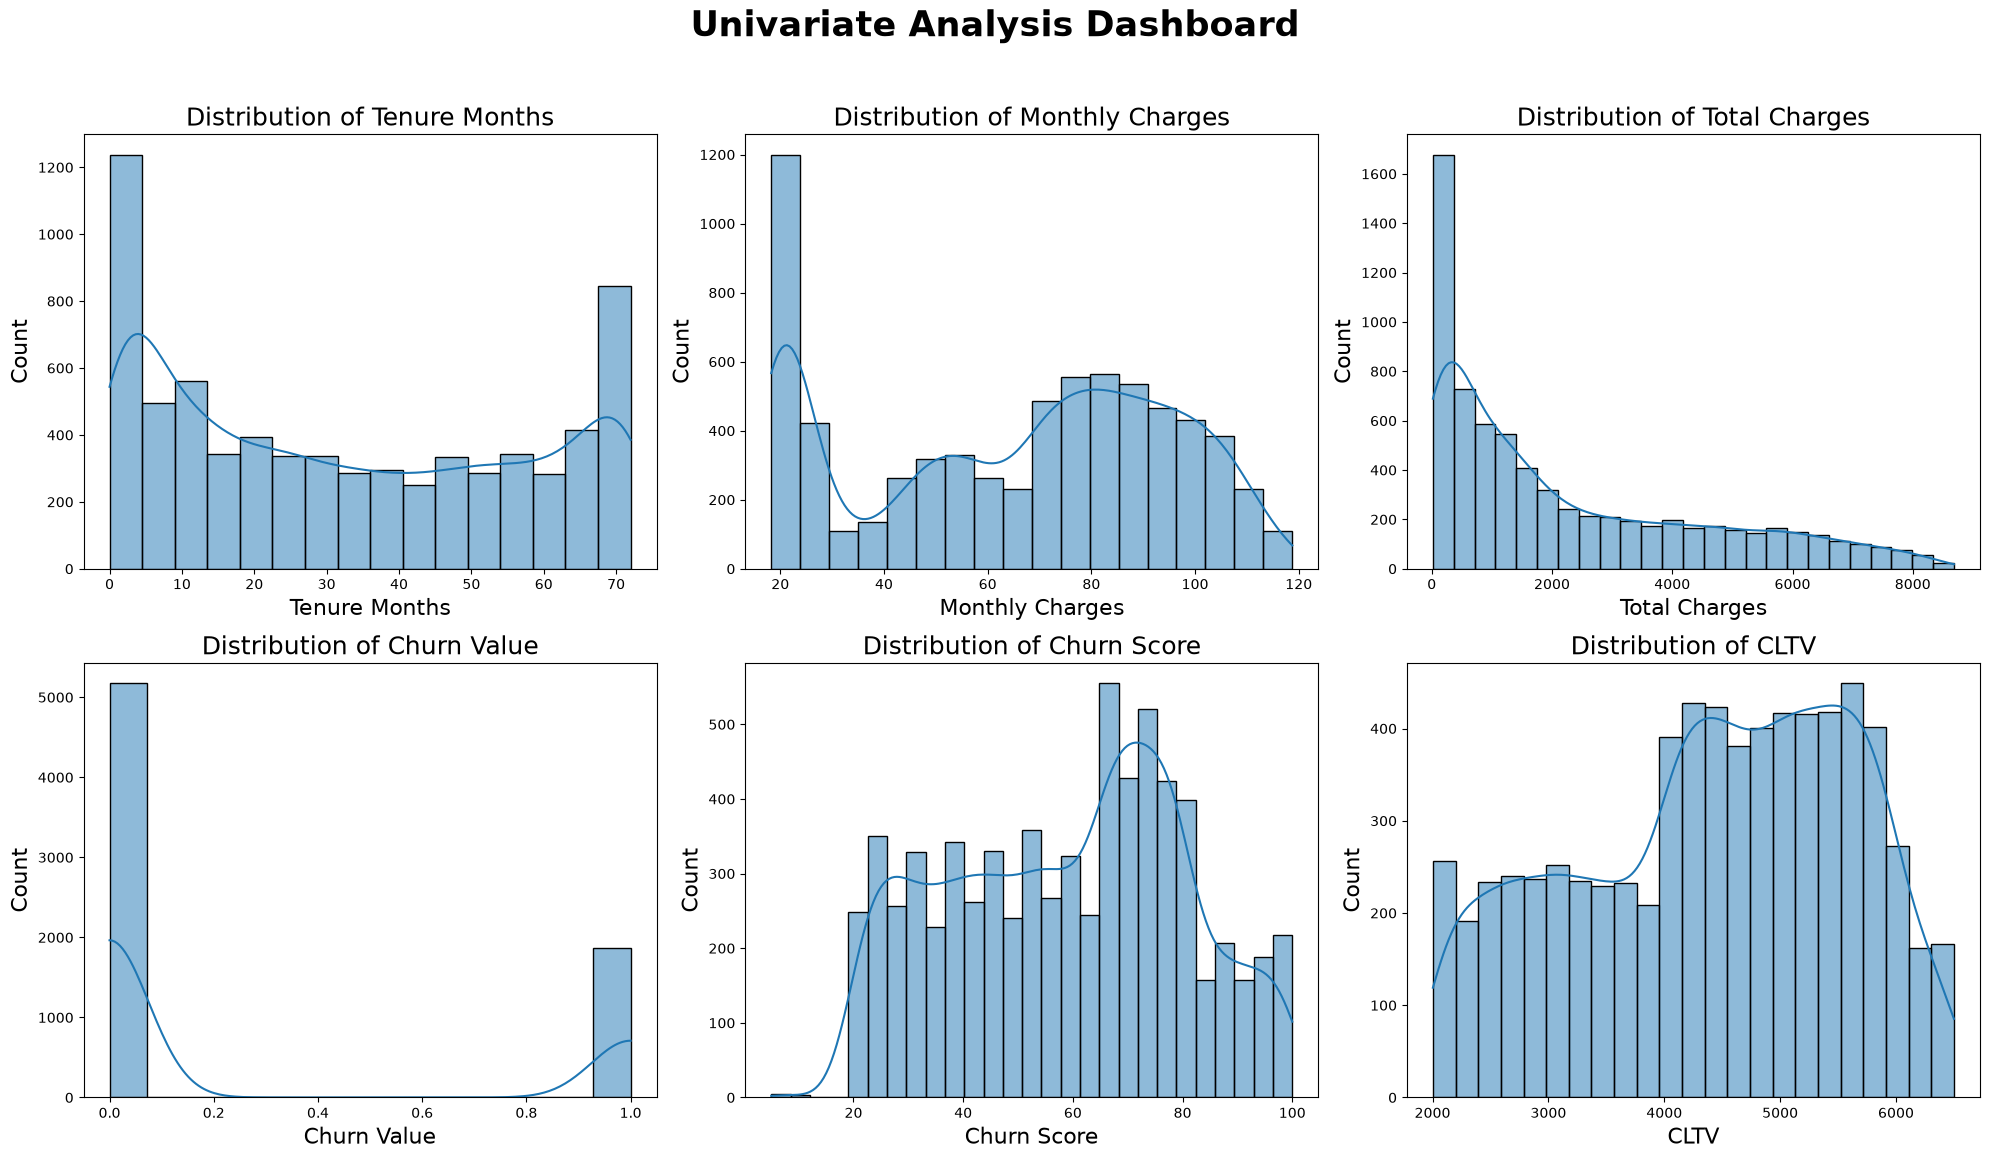

In [205]:
fig, axes=plt.subplots(3,3, figsize=(20,16))
axes=axes.flatten()


for i, var in enumerate(numerical_cols):
    sns.histplot(data=numerical_cols, x=var, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {var}", fontsize=18)
    axes[i].set_xlabel(f"{var}", fontsize=16)
    axes[i].set_ylabel("Count", fontsize=16)

for j in range(len(numerical_cols.columns), len(axes)):
    fig.delaxes(axes[j])


plt.suptitle("Univariate Analysis Dashboard", fontsize=25, weight='bold',y=1.02)
plt.tight_layout()
plt.show()

## Analysis:
-  Tenure Months: U-shaped histogram shows stay 0-5 months mostly or loyal customers around 70 months. If customers pass they initial months, they can be the loyal customers.
- Monthly Charges: Huge spike of customers paying basic plans of around 20Dollar  per month. Premium customers are paying $70 to $100 per month.
 <br>


- Total Charges: Total money spent over the lifetime is showing a spike around 0 means most of the customers are low tenure. Premium customers have spent $6000-$8000.
- Churn Value: Binary variable stored as numerical shows majority of the customers have stayed with the company.
- Churn Score: A major peak between 65 to 80 shows most of the customers have a moderate to high risk of churn.
- CLTV (Customer Lifetime Value): There is a peak around $4000 to $6000, means majority of the customers hold financial value



In [206]:
numerical_cols.skew().sort_values(ascending=False)

Churn Value        1.063031
Total Charges      0.963789
Tenure Months      0.239540
Churn Score       -0.089840
Monthly Charges   -0.220524
CLTV              -0.311602
dtype: float64

#### Analysis:
-  **Total Charges** has right skewness

#### Define categorical columns

In [14]:
categorical_cols=churn.select_dtypes(include='object')
categorical_cols.head()

,City,Gender,Senior Citizen,Partner,Dependents,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Churn Reason
0,Los Angeles,Male,No,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,Competitor made better offer
1,Los Angeles,Female,No,No,Yes,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,Moved
2,Los Angeles,Female,No,No,Yes,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,Moved
3,Los Angeles,Female,No,Yes,Yes,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,Moved
4,Los Angeles,Male,No,No,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),Competitor had better devices


In [208]:
categorical_cols.shape

(7043, 18)

#### Plot categorical columns

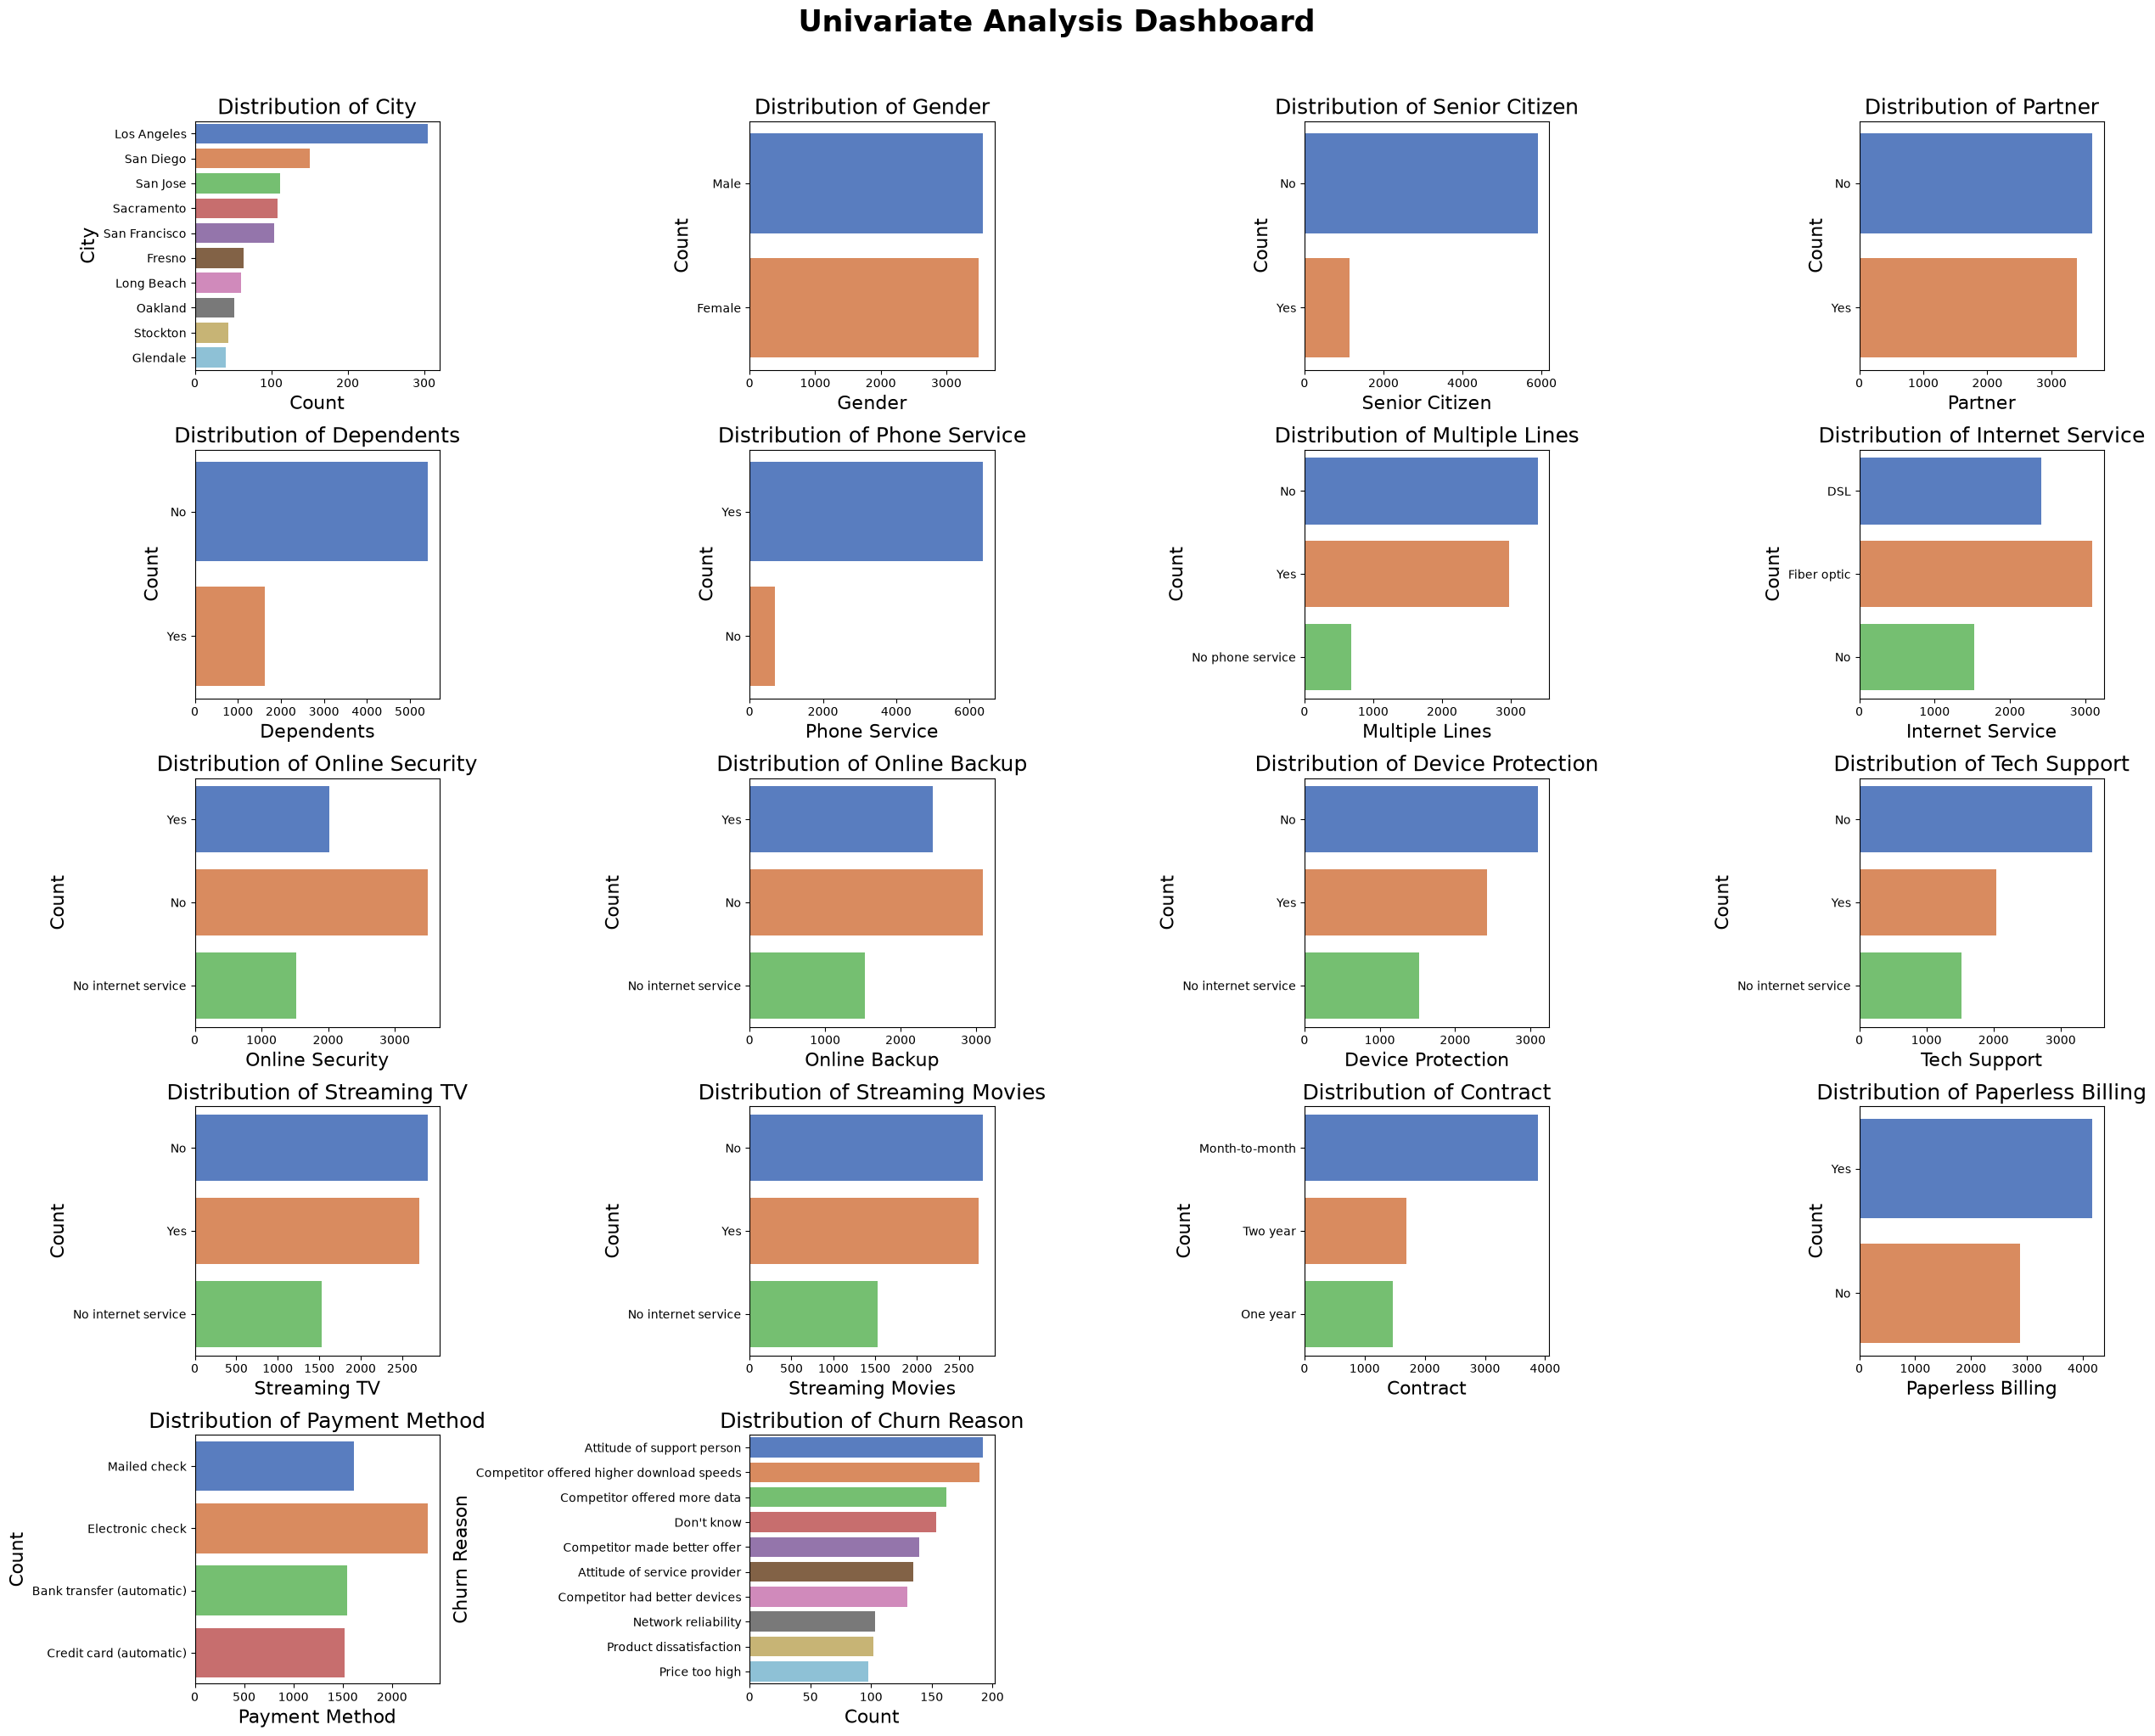

In [209]:
fig, axes=plt.subplots(5,4, figsize=(25,20))
axes=axes.flatten()

for i, var in enumerate(categorical_cols):
    if categorical_cols[var].nunique()>10: # if number of levels of a variable is more than 10
        top_10=categorical_cols[var].value_counts()[:10]
        sns.barplot(top_10,orient='h',ax=axes[i], palette='muted' ) # create a barplot for them
        axes[i].set_title(f"Distribution of {var}", fontsize=18)
        axes[i].set_ylabel(f"{var}", fontsize=16)
        axes[i].set_xlabel("Count", fontsize=16)
    else:
        sns.countplot(data=categorical_cols, y=var, ax=axes[i], palette="muted") #Otherwise create countplot
        axes[i].set_title(f"Distribution of {var}", fontsize=18)
        axes[i].set_xlabel(f"{var}", fontsize=16)
        axes[i].set_ylabel("Count", fontsize=16)

# Clean up empty subplots
for j in range(len(categorical_cols.columns),len(axes)):
     fig.delaxes(axes[j])

plt.suptitle("Univariate Analysis Dashboard", fontsize=25, weight='bold',y=1.02)
plt.tight_layout()
plt.show()

### Customer Demographics & Profile
- City: Most of the customers are from Los Angele and San Diego.
- Gender and Partner: Gender is a 50/50 ratio and so is the partner.
- Senior Citizen and Dependants: Majority of the customers are not senior citizen and do not have dependants.
### Core Telecom Services
- Phone and Multiple Lines: Most of the customers have phone service and massive majority has multiple lines.
- Internet Services: Fibre is more popular than DSL.
### Add-on Services
- Online Security, Online Backup, Device Protection, and Tech Support:
•	Most of the customers do not have these services. Unprotected customers who experience technical issues or data loss are much more likely to leave the company out of frustration.
### Billing, Contracts, & Risk Factors
- Contract: Most of the customers are month-to-month, they can cancel their services any time.
- Payment Method & Paperless Billing:  Most customers use paperless billing. Electronic Check is the most popular method; these are the high risk customers as they have to manually process the payment or think about the payment every month.
### Why Customers Leave: Churn Reason: 
Attitude of support person and competitor offered higher download speed are the top 2 reasons for customer churn.


### Outlier detection: Use the Tukey method to identify outliers.

In [210]:
# Extreme Tukey method
#lower outer fence: Q1 - 3*IQR
#upper outer fence: Q3 + 3*IQR
def outlier_analysis_Tukey(df,col):
    """
    in this function, distribution( visulization as well as summerization) of only outliers is shown.
    Extreme tukey method is selected
    
    """
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    UOF=Q3+3*(IQR)#UOF is upper outer fence
    LOF=Q1-3*(IQR)#LIF is lower outer fence
    df_out =df[(df[col]<LOF) | (df[col]>UOF)] # Create a new data set of potential outliers
    sns.distplot(df[col])
    return df_out[col] .describe()

In [211]:
numerical_cols.columns

Index(['Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Value',
       'Churn Score', 'CLTV'],
      dtype='object')

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Tenure Months, dtype: float64

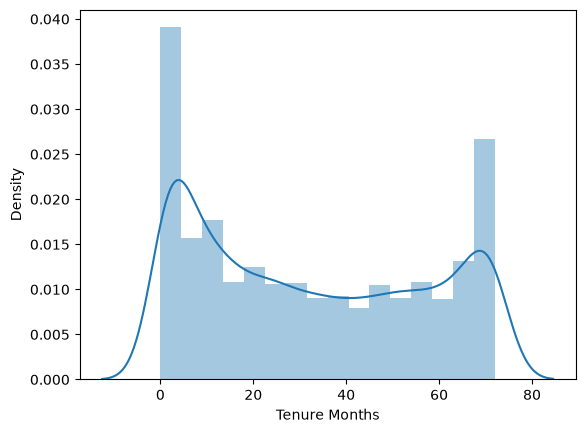

In [212]:
outlier_analysis_Tukey(churn,'Tenure Months')

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Monthly Charges, dtype: float64

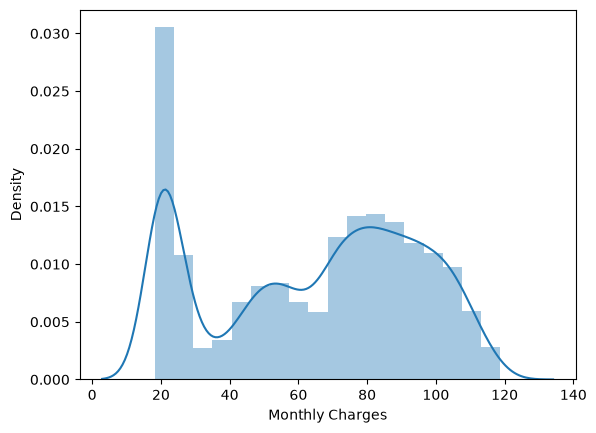

In [213]:
outlier_analysis_Tukey(churn,'Monthly Charges')

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Total Charges, dtype: float64

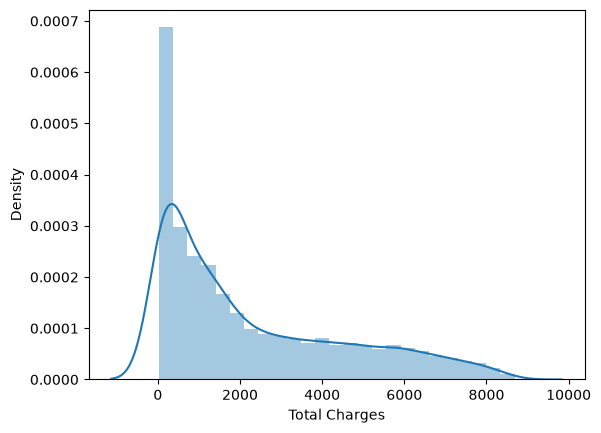

In [214]:
outlier_analysis_Tukey(churn,'Total Charges')

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Churn Score, dtype: float64

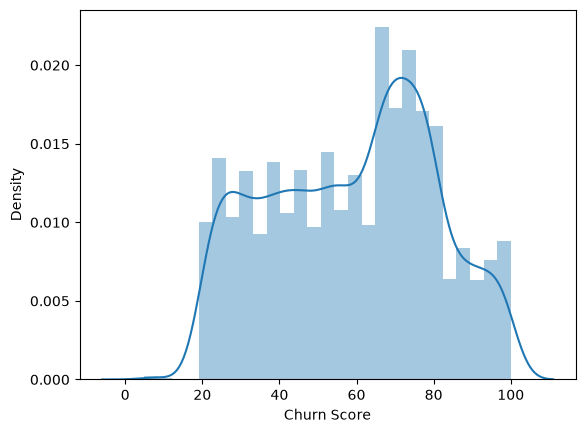

In [215]:
outlier_analysis_Tukey(churn,'Churn Score')

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: CLTV, dtype: float64

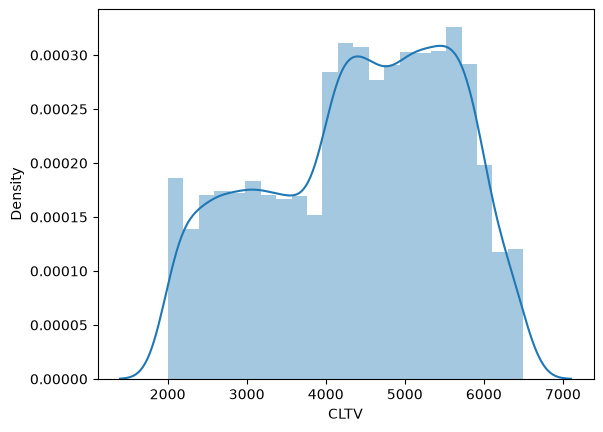

In [216]:
outlier_analysis_Tukey(churn,'CLTV')

### -	Bivariate analysis: Perform at least one analysis for each of the following hypothesis tests:
#### - Chi-square test to assess independence between two categorical variables.


In [217]:
categorical_cols.columns

Index(['City', 'Gender', 'Senior Citizen', 'Partner', 'Dependents',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Churn Reason'],
      dtype='object')

#### Association between 'Senior Citizen' and 'Paperless Billing'

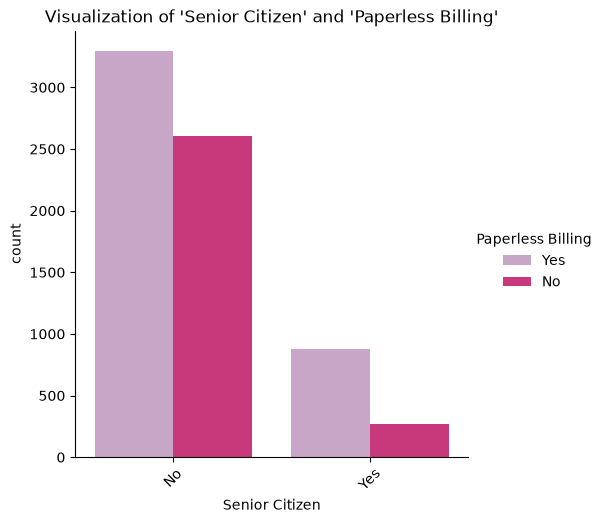

In [218]:
sns.catplot(hue='Paperless Billing', data=categorical_cols, kind='count', x='Senior Citizen', palette='PuRd')

plt.xticks(rotation=45)
plt.title("Visualization of 'Senior Citizen' and 'Paperless Billing'")
plt.show()

### Non-Senior Citizens: 56% of non-senior customers use paperless billing while 56% rely on paper bills.
### Senior Citizens: Majority of senior citizens choose paperless billing.
## Analysis: If the digital invoicing system or mobile app has a confusing user interface, it will directly impact this vulnerable customer segment including senior citizens.


In [219]:
contingency_table1 = pd.crosstab(categorical_cols['Senior Citizen'],categorical_cols['Paperless Billing'],margins = True)
contingency_table1

Paperless Billing,No,Yes,All
Senior Citizen,,,
No,2606,3295,5901
Yes,266,876,1142
All,2872,4171,7043


#### Chi-squared test of independence
##### The Null and Alternate Hypotheses


- H0:There is no statistically significant relationship between basement and property_type.

- Ha:There is a statistically significant relationship between basement and property_type.

##### Assumption:
The Chi-square test statistic can be used if the following conditions are satisfied:

1. N, the total frequency, should be reasonably large, say greater than 50.

2. The sample observations should be independent. This implies that no individual item should be included twice or more in the sample.
   
3. No expected frequencies should be small. Small is a relative term. Preferably each expected frequencies should be larger than 10 but in any case not less than 5.

In [220]:
def chi_square(df,c1,c2):
    chi_2, p_val, dof, exp_val = chi2_contingency(pd.crosstab(df[c1],df[c2],margins = False))# make sure margins = False
    print("Actual values:\n")
    print(pd.crosstab(df[c1],df[c2],margins = False))
    print("="*100)
    print("Expected values: \n")
    print(exp_val)
    print("="*100)
    
    #print('\nChi-square is : %f'%chi_2, '\n\np_value is : %f'%p_val, '\n\ndegree of freedom is : %i'%dof)
    print(f'\nChi-square is : {chi_2}', f'\n\np_value is : {p_val}', f'\n\ndegree of freedom is :{dof}')
    print("="*100)
    if exp_val.min()<5 or np.sum(exp_val)<50 : print("\n********************************************\nWarning :We have some small expected \
values or the total number of observations is not enough to get any conclusion\n******************************************** ")
        #Note for sum of all values in dataframe use df.values.sum() and for numpy.ndarray use np.sum(arr)
    elif p_val < 0.05:# consider significan level is 5%
        print(F"\nThere is statistiacally significant correlation between {c1} and {c2} at 0.05 significant level")
    else:
        print(F"\nThere is no correlation between the two variables( we don't have enough evidence to conclude there is a a statistically significant relationship between {c1} and {c2}")        

In [221]:
chi_square(categorical_cols,'Senior Citizen', 'Paperless Billing')

Actual values:

Paperless Billing    No   Yes
Senior Citizen               
No                 2606  3295
Yes                 266   876
Expected values: 

[[2406.31435468 3494.68564532]
 [ 465.68564532  676.31435468]]

Chi-square is : 171.70098839824468 

p_value is : 3.1453154718475934e-39 

degree of freedom is :1

There is statistiacally significant correlation between Senior Citizen and Paperless Billing at 0.05 significant level


#### Cramer's V

In [222]:
def cramers_V(var1,var2) :
  crosstab =np.array(pd.crosstab(var1,var2, rownames=None, colnames=None)) # Cross table building
  stat = chi2_contingency(crosstab)[0] # Keeping of the test statistic of the Chi2 test
  obs = np.sum(crosstab) # Number of observations
  mini = min(crosstab.shape)-1 # Take the minimum value between the columns and the rows of the cross table
  return np.sqrt((stat/(obs*mini)))

In [223]:
cramers_V(categorical_cols['Senior Citizen'],categorical_cols['Paperless Billing'])

np.float64(0.15613761937212736)

### Although there is statistically significant correlation between Senior Citizen and Paperless Billing but it is not strong, 0.15 is a weak association

In [224]:
rows=[]

for var1 in categorical_cols.columns:
    col=[]
    for var2 in categorical_cols.columns:
        cramers=cramers_V(categorical_cols[var1], categorical_cols[var2]) # apply Cramer's V test
        col.append(round(cramers,2)) # append the values onto columns of dataframe
    rows.append(col)

cramers=np.array(rows)
df_cramers=pd.DataFrame(cramers, columns=categorical_cols.columns, index=categorical_cols.columns)

In [225]:
df_cramers

,City,Gender,Senior Citizen,Partner,Dependents,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Churn Reason
City,1.00,0.40,0.40,0.41,0.41,0.39,0.40,0.40,0.40,0.41,0.40,0.41,0.40,0.41,0.41,0.39,0.40,0.66
Gender,0.40,1.00,0.00,0.00,0.00,0.01,0.01,0.01,0.02,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.02,0.10
Senior Citizen,0.40,0.00,1.00,0.02,0.17,0.01,0.15,0.27,0.21,0.18,0.18,0.22,0.19,0.19,0.14,0.16,0.20,0.12
Partner,0.41,0.00,0.02,1.00,0.36,0.02,0.14,0.00,0.15,0.15,0.17,0.13,0.14,0.13,0.30,0.01,0.16,0.09
Dependents,0.41,0.00,0.17,0.36,1.00,0.00,0.03,0.20,0.21,0.19,0.18,0.20,0.17,0.17,0.20,0.12,0.14,0.10
Phone Service,0.39,0.01,0.01,0.02,0.00,1.00,1.00,0.45,0.18,0.17,0.17,0.18,0.18,0.18,0.00,0.02,0.01,0.11
Multiple Lines,0.40,0.01,0.15,0.14,0.03,1.00,1.00,0.40,0.23,0.25,0.25,0.23,0.26,0.26,0.08,0.17,0.17,0.12
Internet Service,0.40,0.01,0.27,0.00,0.20,0.45,0.40,1.00,0.72,0.71,0.71,0.72,0.72,0.72,0.21,0.38,0.31,0.12
Online Security,0.40,0.02,0.21,0.15,0.21,0.18,0.23,0.72,1.00,0.72,0.72,0.73,0.71,0.71,0.30,0.34,0.30,0.10
Online Backup,0.41,0.01,0.18,0.15,0.19,0.17,0.25,0.71,0.72,1.00,0.72,0.72,0.71,0.71,0.26,0.32,0.28,0.12


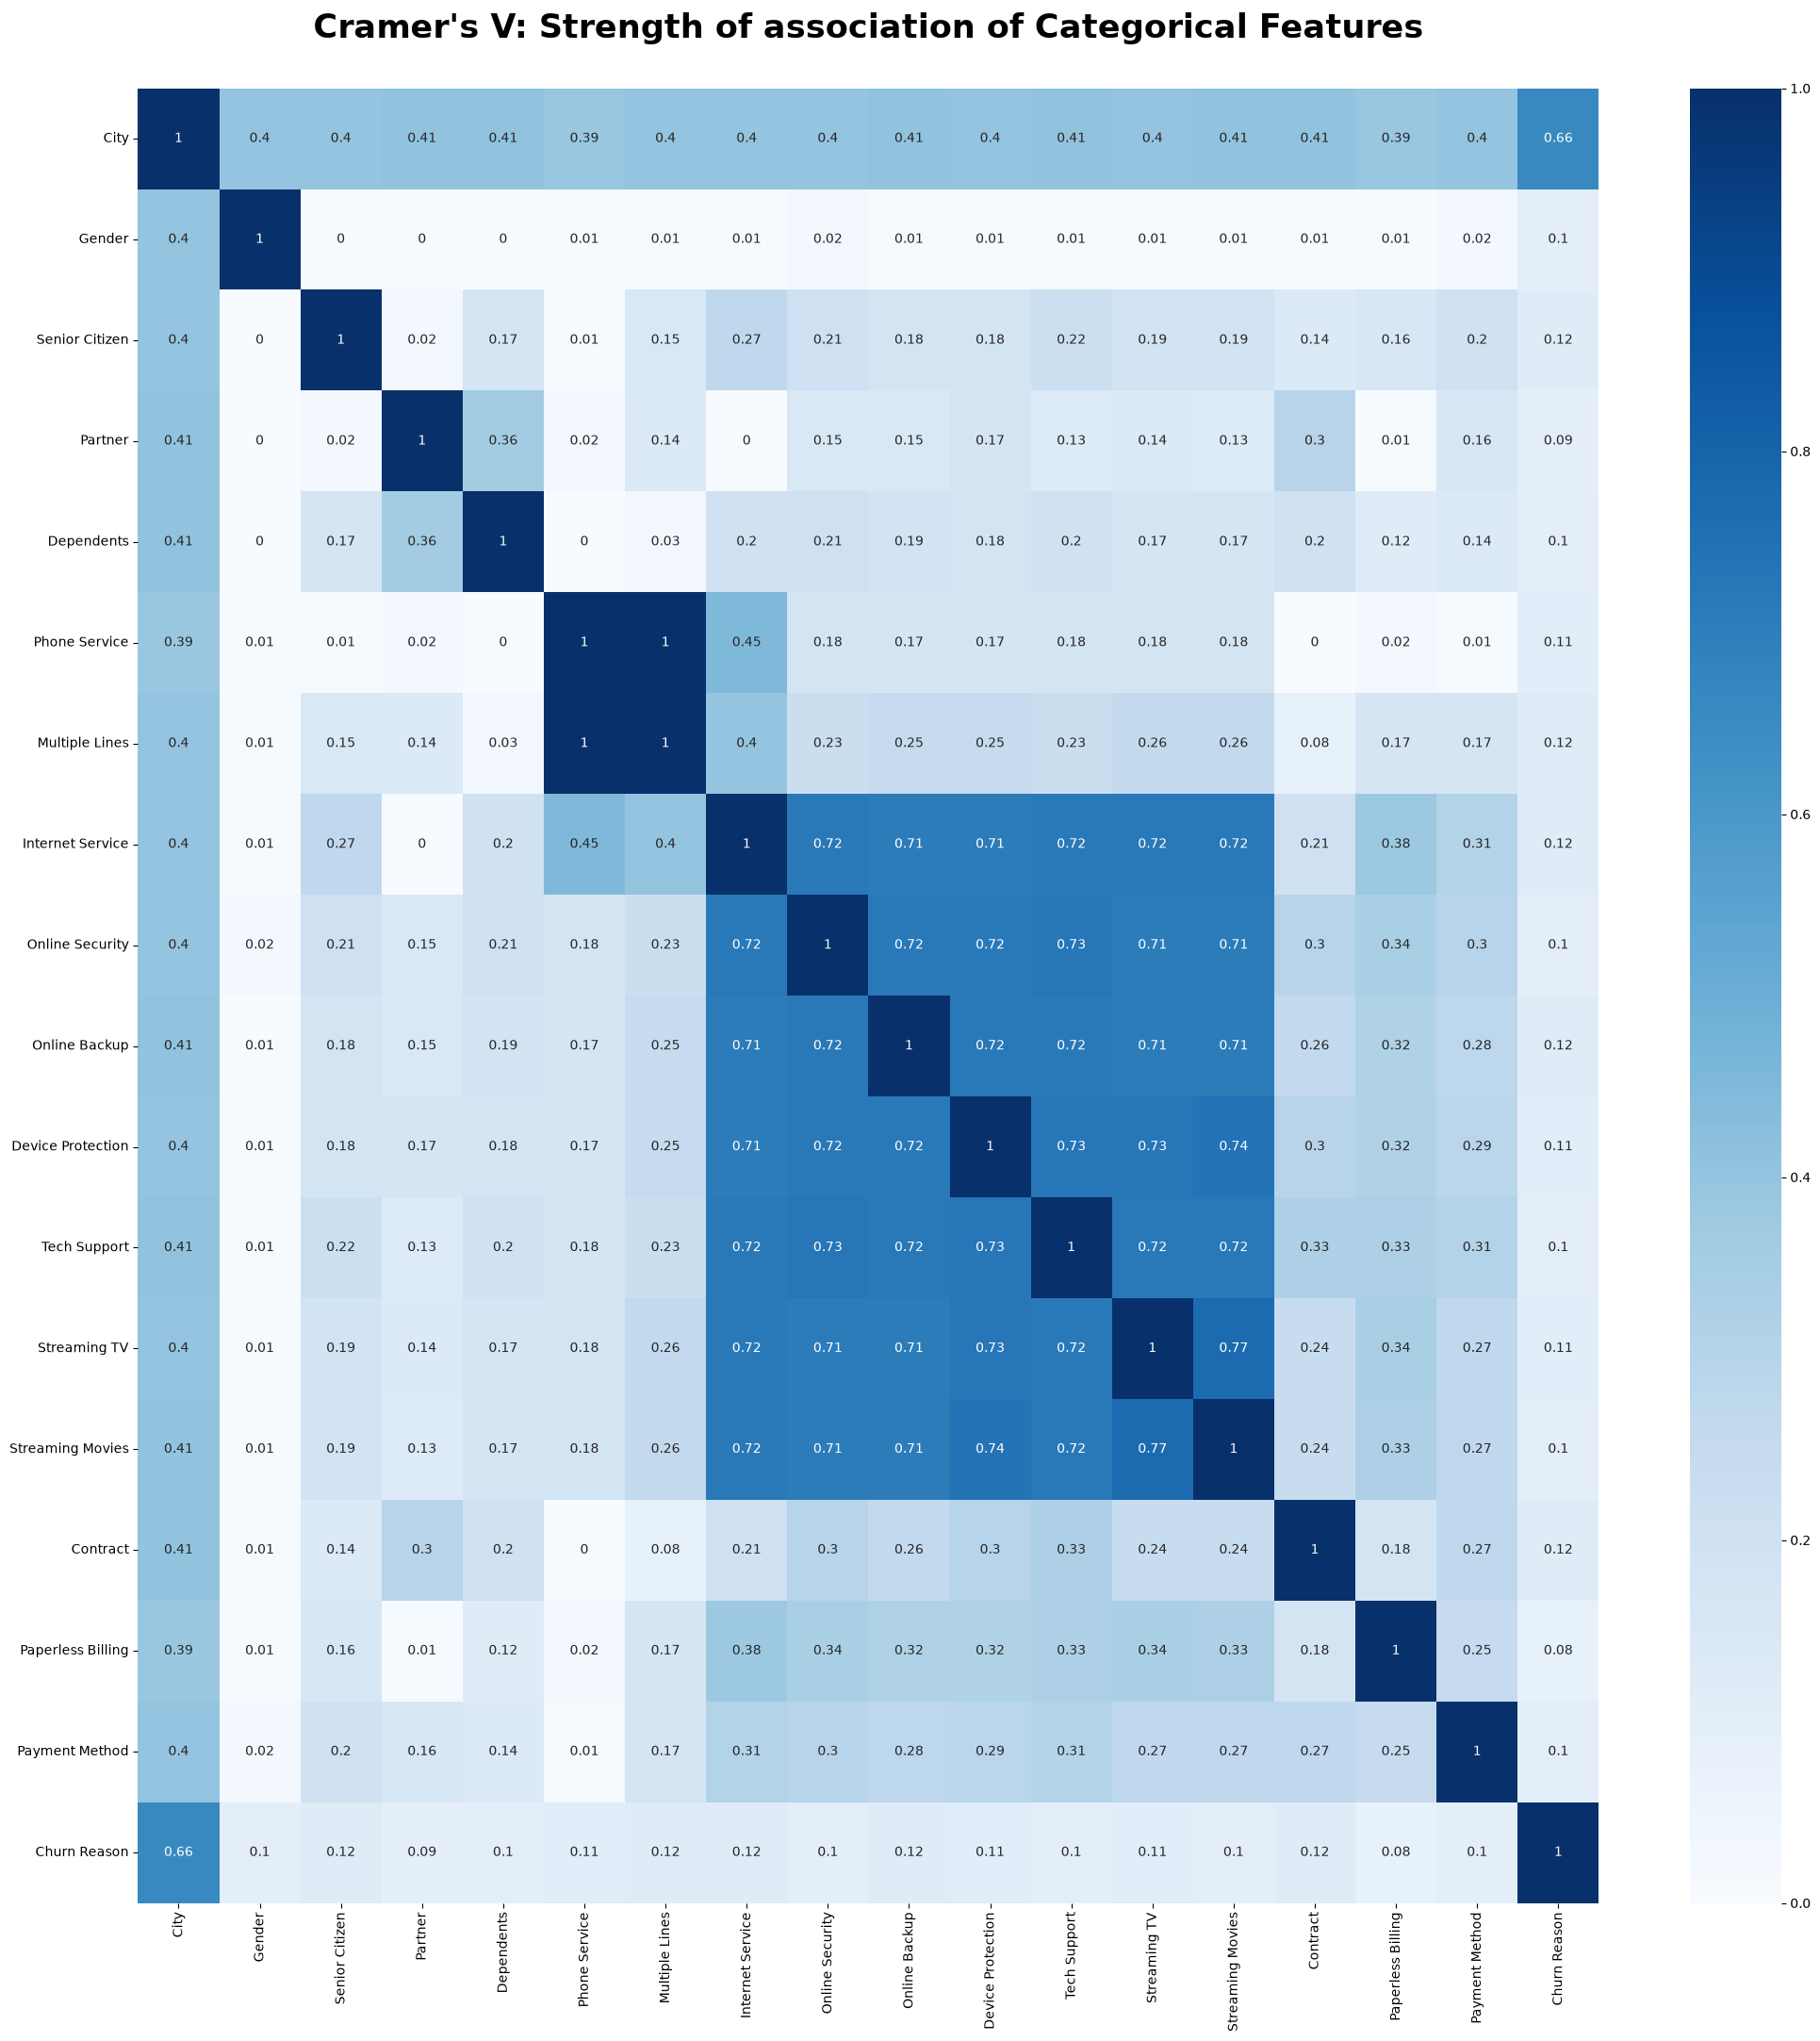

In [226]:
plt.figure(figsize=(25,25))

sns.heatmap(df_cramers, cmap='Blues', annot=True)
plt.title("Cramer's V: Strength of association of Categorical Features\n", fontsize=25,weight='bold')

plt.show()

#### 	Correlation analysis to examine relationships between two numeric variables.

In [227]:
corr = numerical_cols.corr()
corr.style.background_gradient(cmap='coolwarm')
# 'RdBu_r', 'BrBG_r', & PuOr_r are other good diverging colormaps

,Tenure Months,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV
Tenure Months,1.000000,0.247900,0.825464,-0.352229,-0.224987,0.396406
Monthly Charges,0.247900,1.000000,0.650864,0.193356,0.133754,0.098693
Total Charges,0.825464,0.650864,1.000000,-0.199037,-0.123948,0.341723
Churn Value,-0.352229,0.193356,-0.199037,1.000000,0.664897,-0.127463
Churn Score,-0.224987,0.133754,-0.123948,0.664897,1.000000,-0.079782
CLTV,0.396406,0.098693,0.341723,-0.127463,-0.079782,1.000000


## Analysis
- There is a strong correlation between churn score and Churn Value i.e. +0.66
- Monthly Charges and Churn Value have a weak positive correlation of 0.19.
- Tenure Months and Total Charges have high correlation of +0.83 means longer the tenure with the company, higher are the charges.


#### 	T-test or similar test to compare means/median between two groups.
#### Categorical vs Continuous: Summarization

In [228]:
churn.dtypes

City                  object
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges        float64
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason          object
dtype: object

In [229]:
churn['Dependents'].value_counts()

Dependents
No     5416
Yes    1627
Name: count, dtype: int64

In [230]:
churn.groupby('Dependents').agg({'CLTV':'mean'})

,CLTV
Dependents,
No,4362.545975
Yes,4525.958205


#### Visulization: grouped boxplot

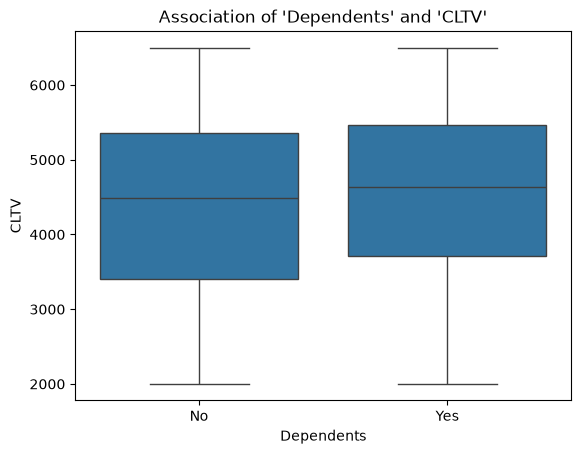

In [15]:
sns.boxplot(data=churn, x='Dependents', y='CLTV')
plt.title("Association of 'Dependents' and 'CLTV'")
plt.show()

## Analysis: 
A comparison of household structure and Customer Lifetime value (CLTV) shows there is no evidence of association between the two variables. So, policies for customers with dependents and without dependents should produce the same output. The median of the two groups is almost overlapping.

#### 'Dependents' has two levels, divide them into two dataframe

In [232]:
dep=churn[churn['Dependents']=='Yes']
no_dep=churn[churn['Dependents']=='No']
dep.head(3)

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason
1,Los Angeles,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,67,2701,Moved
2,Los Angeles,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1,86,5372,Moved
3,Los Angeles,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1,84,5003,Moved


In [233]:
no_dep.head(3)

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason
0,Los Angeles,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,86,3239,Competitor made better offer
5,Los Angeles,Female,No,Yes,No,10,Yes,No,DSL,No,No,Yes,Yes,No,No,Month-to-month,No,Credit card (automatic),55.20,528.35,1,78,5925,Competitor offered higher download speeds
6,Los Angeles,Male,Yes,No,No,1,No,No phone service,DSL,No,No,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,39.65,39.65,1,100,5433,Competitor offered more data


#### T-Test between 'CLTV' and 'Dependents'
##### The T-Test is used to determine if the mean (average) of two groups are truly different. The t test (also called Student’s T Test) compares two averages (means) and tells you if they are different from each other. The t test also tells you how significant the differences are; In other words it lets you know if those differences could have happened by chance.

**Null Hypothesis:** There is no difference in means of CLTV for customers with dependents and without dependents,(the means of both populations are equal)

**Alternate Hypothesis:** There is a statistically significant difference in means of CLTV for customers with dependents and without dependents (the means of both populations are not equal)

There are three assumptions that need to be met.

Assumption 1: Are the two samples independent( here means mutually exclusivce)?<br>
Assumption 2: Are the data from each of the 2 groups following a normal distribution?<br>
Assumption 3: Do the two samples have the same variances (Homogeneity of Variance)?<br>
Besides them we are not allowd to have significant outliers

#### Assumption 1: Are the two samples independent( here means mutually exclusive)?
Since customers with dependents and without dependents are two mutually exclusive groups, so this assumption is satisfied

#### Assumption 2: Are the data from each of the 2 groups following a normal distribution?
NORMALITY:Are the data from each of the 2 groups following a normal distribution?
    Rely on the Central Limit Theorem if the sample size is large enough (n>30)

#### Assumption 3: Do the two samples have the same variances (Homogeneity of Variance)?

In [234]:
# drop missing values
dep=dep.drop(dep[dep['CLTV'].isnull()].index)
no_dep=no_dep.drop(no_dep[no_dep['CLTV'].isnull()].index)
a=dep['CLTV']
b=no_dep['CLTV']

#### H0: variance of a is equal to variance of b
#### H1: variance of a is not equal to variance of b

In [235]:
levene(a,b)

LeveneResult(statistic=np.float64(3.2095567398519864), pvalue=np.float64(0.07325224424950601))

#### p-value=0.07>0.05 so fail to reject H0, means variance of a is equal to variance of b

In [236]:
tStat, pValue = ttest_ind(a, b, equal_var = False) #equal_var = False runs independent sample T-Test for unequal variance(Welch’s t-test)
print("P-Value:{0} T-Statistic:{1}".format(pValue,tStat))#print the P-Value and the T-Statistic

P-Value:8.135161206587004e-07 T-Statistic:4.94360386053403


### p-value for ttest=8.13e-07<0.05 so reject H0 that There is no difference in means of CLTV for customers with dependents and without dependents.
####  Conclude: There is a statistically significant difference in means of CLTV for customers with dependents and without dependents

### 	Analysis of Variance (ANOVA) or similar test to compare means/median across multiple groups.

#### Analysis of variance (ANOVA) uses F-tests to statistically assess the equality of means when you have three or more groups.

PARAMETRIC ASSUMPTIONS
Parametric tests have the same assumptions, or conditions, that need to be met in order for the analysis to be considered reliable.<br>

Parametric test assumptions:<br>
1. Independence
2. Population distributions are normal(normality)
3. Samples have equal variances(HOMOGENEITY OF VARIANCES)
4. samples doesn't have significant outliers
It is best to check the assumptions in the order above since some equal variance tests are sensitive to the distribution being normal.

### *****************ANOVA Test : 'Contract' vs 'Total Charges'****************
##### H0: There is no difference in means of Total Charges for all the groups of Contract
##### H1: At least one group of Contract has different mean than others

In [237]:
churn.dtypes

City                  object
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges        float64
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason          object
dtype: object

In [238]:
churn.Contract.value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [239]:
churn['Churn Score'].isna().sum()

np.int64(0)

In [240]:
grp1=churn[churn['Contract']=='Month-to-month']['Total Charges']
grp2=churn[churn['Contract']=='Two year']['Total Charges']
grp3=churn[churn['Contract']=='One year']['Total Charges']

In [241]:
kstest(grp1, 'norm')

KstestResult(statistic=np.float64(1.0), pvalue=np.float64(0.0), statistic_location=np.float64(18.85), statistic_sign=np.int8(-1))

In [242]:
kstest(grp2, 'norm')

KstestResult(statistic=np.float64(1.0), pvalue=np.float64(0.0), statistic_location=np.float64(20.35), statistic_sign=np.int8(-1))

In [243]:
kstest(grp3, 'norm')

KstestResult(statistic=np.float64(1.0), pvalue=np.float64(0.0), statistic_location=np.float64(18.8), statistic_sign=np.int8(-1))

## p-value is less than 5% but rely on CLT, skip normality assumption or do transformation or run Kruskal-Wallis test 

### **Checking Outliers**
- **No outliers in categorical and numerical variable

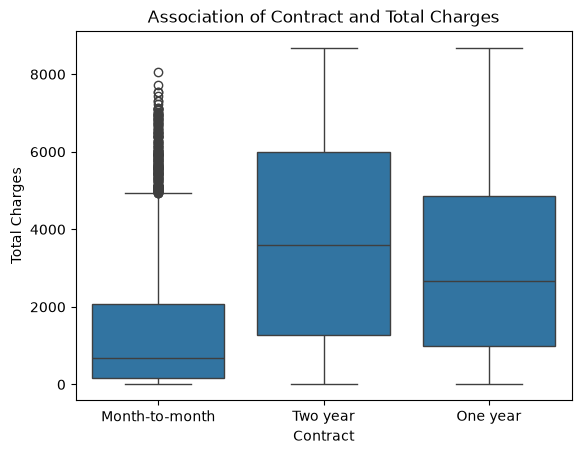

In [16]:
sns.boxplot(x='Contract', y='Total Charges', data=churn)
plt.title('Association of Contract and Total Charges')
plt.show()

## Analysis:
This chart shows the median Total Charges for three types of contract are different as compared to the previous boxplot.
- Month-to-Month: Median spending is around $1000 with many customers whose spending is more than $5000, means they are long-term customers but still on a month-to-month contract. These are the outliers in the box plot.
- Two-Year Contract: The median total charge is around $3,600, and the top half of this segment is up to $6,000 to $8,500. These are the long-term customers.
  
- One-Year Contract: This group has median Total Charge around $2600.


count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Total Charges, dtype: float64

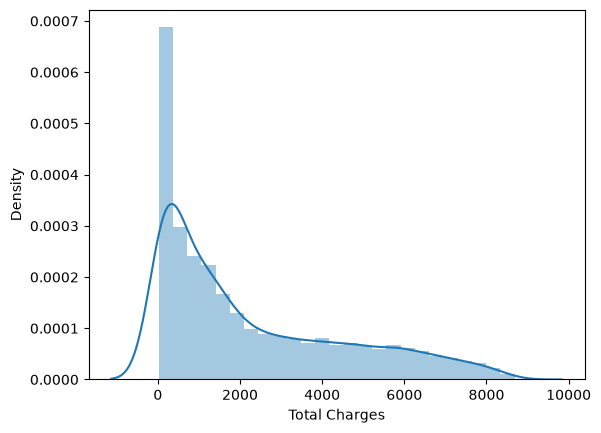

In [245]:
outlier_analysis_Tukey(churn,'Total Charges')

In [246]:
levene(churn['Total Charges'][churn['Contract'] == 'Month-to-month'],
             churn['Total Charges'][churn['Contract'] == 'Two year'],
             churn['Total Charges'][churn['Contract'] == 'One year'])

LeveneResult(statistic=np.float64(555.9156704999878), pvalue=np.float64(6.878704236025719e-225))

### Apply Welch ANOVA

In [247]:

pg.welch_anova(dv='Total Charges', between='Contract', data=churn)

,Source,ddof1,ddof2,F,p_unc,np2
0,Contract,2,2759.124986,822.544803,6.529230e-281,0.208709


#### p-value=6.529230e-281<0.05 so reject H0: There is no difference in means of Total Charges for all the groups of Contract
#### conclude: At least one group has means different

In [248]:
pt = pg.pairwise_tukey(dv='Total Charges', between='Contract', data=churn)
print(pt)

                A         B       mean_A       mean_B         diff         se  \
0  Month-to-month  One year  1369.254581  3033.571606 -1664.317025  61.689071   
1  Month-to-month  Two year  1369.254581  3715.179027 -2345.924446  58.688992   
2        One year  Two year  3033.571606  3715.179027  -681.607421  71.788705   

           T       p_tukey    hedges  
0 -26.979123  5.234702e-13 -0.922224  
1 -39.972137  5.234702e-13 -1.199892  
2  -9.494633  5.234702e-13 -0.281877  


### Analysis: All groups have different means

In [249]:
churn.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason
0,Los Angeles,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,86,3239,Competitor made better offer
1,Los Angeles,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,67,2701,Moved
2,Los Angeles,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1,86,5372,Moved
3,Los Angeles,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1,84,5003,Moved
4,Los Angeles,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1,89,5340,Competitor had better devices


# Sentiment Analysis

### 'Churn Reason' has 73.4% of missing values

In [17]:
churn['Churn Reason'].value_counts(normalize=True, dropna=False).sort_values(ascending=False)

Churn Reason
NaN                                          0.734630
Attitude of support person                   0.027261
Competitor offered higher download speeds    0.026835
Competitor offered more data                 0.023002
Don't know                                   0.021866
Competitor made better offer                 0.019878
Attitude of service provider                 0.019168
Competitor had better devices                0.018458
Network reliability                          0.014624
Product dissatisfaction                      0.014482
Price too high                               0.013915
Service dissatisfaction                      0.012637
Lack of self-service on Website              0.012495
Extra data charges                           0.008093
Moved                                        0.007525
Limited range of services                    0.006247
Lack of affordable download/upload speed     0.006247
Long distance charges                        0.006247
Poor expertise 

### Fill the missing values with 'No Churn' as they are active customers

In [18]:
churn['Churn Reason']=churn['Churn Reason'].fillna('No Churn')
churn['Churn Reason'].value_counts()

Churn Reason
No Churn                                     5174
Attitude of support person                    192
Competitor offered higher download speeds     189
Competitor offered more data                  162
Don't know                                    154
Competitor made better offer                  140
Attitude of service provider                  135
Competitor had better devices                 130
Network reliability                           103
Product dissatisfaction                       102
Price too high                                 98
Service dissatisfaction                        89
Lack of self-service on Website                88
Extra data charges                             57
Moved                                          53
Limited range of services                      44
Lack of affordable download/upload speed       44
Long distance charges                          44
Poor expertise of phone support                20
Poor expertise of online support     

### Filter out the rows that have actual churn reason

In [19]:
churn_text_df=churn[churn['Churn Reason'] != 'No Churn'].copy()
churn_text_df.shape

(1869, 24)

In [20]:
churn_text_df.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,...,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason
0,Los Angeles,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,86,3239,Competitor made better offer
1,Los Angeles,Female,No,No,Yes,2,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,67,2701,Moved
2,Los Angeles,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1,86,5372,Moved
3,Los Angeles,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1,84,5003,Moved
4,Los Angeles,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1,89,5340,Competitor had better devices


### USe NLP to find top 15 churn reasons

In [21]:
from sklearn.feature_extraction.text import CountVectorizer

# max_features=15 keeps only top 15 churn reasons
# remove stopwords of 'English language'
vectorizer=CountVectorizer(stop_words='english', max_features=20)

# fit and transform the churn text
X_churn_reason=vectorizer.fit_transform(churn_text_df['Churn Reason'])

reasons= vectorizer.get_feature_names_out()
# Veiw the top 15 reasons of the churn
print("Top churn Reason keywords: ", reasons.tolist())

Top churn Reason keywords:  ['attitude', 'better', 'competitor', 'data', 'devices', 'dissatisfaction', 'don', 'download', 'higher', 'know', 'lack', 'network', 'offer', 'offered', 'person', 'provider', 'reliability', 'service', 'speeds', 'support']


<Axes: xlabel='count', ylabel='Churn Reason'>

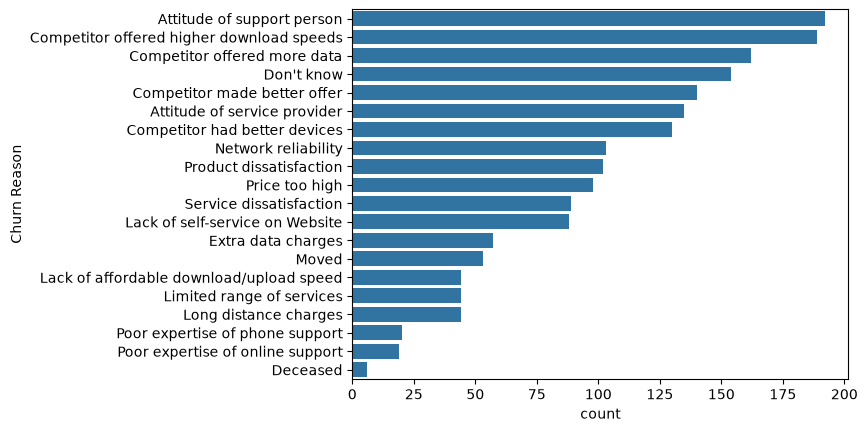

In [255]:
sns.barplot(data=churn_text_df['Churn Reason'].value_counts(), orient='h')

### As the keywords list shows, 'attitude' keyword is the top reason of Churn reason,
- #### competitor is the second most common reason.
- #### Product quality related issues are third in the list
- #### Cost is the fourth reason of Churn.
- #### Rest can be mapped as 'other'

### Define a function for this mapping

In [22]:
def categorize_reason(text):
    text=str(text).lower()
    if 'attitude' in text or 'person' in text or 'service' in text or 'support' in text:
        return 'Poor Service'
    elif 'competitor' in text or 'price' in text or 'offer' in text or 'offered' in text or  'better' in text :
        return 'Competitor'
    elif 'data' in text or  'speeds' in text or 'download' in text  or 'speed' in text or 'network' in text:
        return 'Product Quality'
    elif 'price' in text :
        return 'Price Sensitive'
    elif 'no churn' in text:
        return 'No Churn'
    else:
        return 'Other Reason'
        

### Apply the above defined function to the dataframe

In [23]:
churn['Churn Reason']=churn['Churn Reason'].apply(categorize_reason)
churn['Churn Reason'].value_counts()

Churn Reason
No Churn           5174
Competitor          719
Poor Service        587
Other Reason        359
Product Quality     204
Name: count, dtype: int64

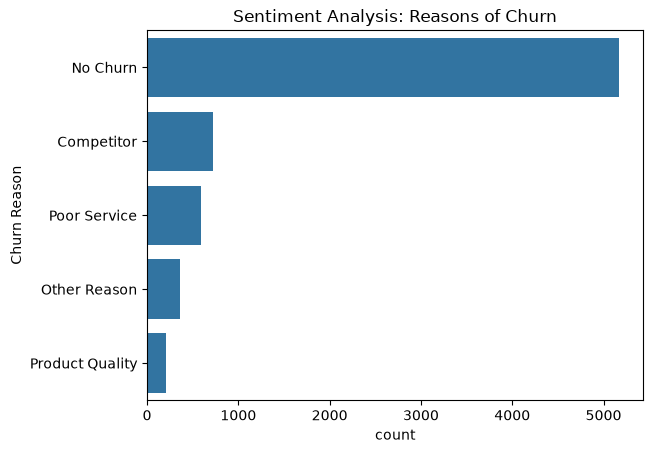

In [26]:
sns.barplot(data=churn['Churn Reason'].value_counts(), orient='h')
plt.title('Sentiment Analysis: Reasons of Churn')
plt.show()

## Analysis:
This shows more than 5000 customers are still with the company. Competitor is the most common keyword in the feedback from the customers; poor service is the second major reason. The marketing and service policies should be designed based on these outcomes.

In [258]:
churn.City.unique()

array(['Los Angeles', 'Beverly Hills', 'Huntington Park', ..., 'Standish',
       'Tulelake', 'Olympic Valley'], shape=(1129,), dtype=object)

#### 'Gender': 'Male':0, 'Female':1

In [259]:
churn['Gender'].value_counts()

Gender
Male      3555
Female    3488
Name: count, dtype: int64

In [260]:
churn['Gender']=churn['Gender'].map({'Male':0,
                    'Female':1})
churn['Gender'].value_counts()

Gender
0    3555
1    3488
Name: count, dtype: int64

### Senior Citizen: 'No':0, 'Yes':1

In [261]:
churn['Senior Citizen'].value_counts()

Senior Citizen
No     5901
Yes    1142
Name: count, dtype: int64

In [262]:
churn['Senior Citizen']=churn['Senior Citizen'].map({'No':0,
                                                    'Yes':1})
churn['Senior Citizen'].value_counts()

Senior Citizen
0    5901
1    1142
Name: count, dtype: int64

### Partner: 'No':0, 'Yes':1

In [263]:
churn['Partner'].value_counts()

Partner
No     3641
Yes    3402
Name: count, dtype: int64

In [264]:
churn['Partner']=churn['Partner'].map({'No':0, 
                                      'Yes':1})
churn['Partner'].value_counts()

Partner
0    3641
1    3402
Name: count, dtype: int64

### Dependents: 'No':0, 'Yes':1

In [265]:
churn['Dependents'].value_counts()

Dependents
No     5416
Yes    1627
Name: count, dtype: int64

In [266]:
churn['Dependents']=churn['Dependents'].map({'No':0,
                                            'Yes':1})
churn['Dependents'].value_counts()

Dependents
0    5416
1    1627
Name: count, dtype: int64

### Phone Service: 'Yes':1,'No':0

In [102]:
churn['Phone Service'].value_counts()

Phone Service
Yes    6361
No      682
Name: count, dtype: int64

In [268]:
churn['Phone Service']=churn['Phone Service'].map({'No':0,
                           'Yes':1})
churn['Phone Service'].value_counts()

Phone Service
1    6361
0     682
Name: count, dtype: int64

### Multiple Lines:'No':0,'Yes':1,'No phone service':2

In [270]:
churn['Multiple Lines'].value_counts()

Multiple Lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

In [271]:
churn['Multiple Lines']=churn['Multiple Lines'].map({'No':0, 
                                                     'Yes':1,
                                                    'No phone service':2})
churn['Multiple Lines'].value_counts()

Multiple Lines
0    3390
1    2971
2     682
Name: count, dtype: int64

### Internet Service: 'No':0, 'Fiber optic':1, 'DSL':2

In [272]:
churn['Internet Service'].value_counts()

Internet Service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [273]:
churn['Internet Service']=churn['Internet Service'].map({'No': 0,
                                                'Fiber optic':1,
                                                'DSL':2})
churn['Internet Service'].value_counts()

Internet Service
1    3096
2    2421
0    1526
Name: count, dtype: int64

### Online Security: 'No':0, 'Yes':1, 'No internet service':2

In [274]:
churn['Online Security'].value_counts()

Online Security
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [275]:
churn['Online Security']=churn['Online Security'].map({'No':0,
                            'Yes':1,
                            'No internet service':2})
churn['Online Security'].value_counts()

Online Security
0    3498
1    2019
2    1526
Name: count, dtype: int64

### 'Online Backup':'No':0, 'Yes':1,'No internet service':2

In [276]:
churn['Online Backup'].value_counts()

Online Backup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

In [277]:
churn['Online Backup']=churn['Online Backup'].map({'No':0,
                           'Yes':1,
                           'No internet service':2})
churn['Online Backup'].value_counts()

Online Backup
0    3088
1    2429
2    1526
Name: count, dtype: int64

### Device Protection: 'No':0, 'Yes':1, 'No internet service':2

In [278]:
churn['Device Protection'].value_counts()

Device Protection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

In [279]:
churn['Device Protection']=churn['Device Protection'].map({'No':0,
                                                          'Yes':1,
                                                          'No internet service':2})
churn['Device Protection'].value_counts()

Device Protection
0    3095
1    2422
2    1526
Name: count, dtype: int64

### Tech Support: 'No':0, 'Yes':1, 'No internet service':2

In [280]:
churn['Tech Support'].value_counts()

Tech Support
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

In [281]:
churn['Tech Support']=churn['Tech Support'].map({'No':0,
                                                'Yes':1,
                                                'No internet service':2})
churn['Tech Support'].value_counts()

Tech Support
0    3473
1    2044
2    1526
Name: count, dtype: int64

### Streaming TV:'No':0, 'Yes':1, 'No internet service':2

In [282]:
churn['Streaming TV'].value_counts()

Streaming TV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

In [283]:
churn['Streaming TV']=churn['Streaming TV'].map({'No':0,
                                               'Yes':1,
                                               'No internet service':2})
churn['Streaming TV'].value_counts()

Streaming TV
0    2810
1    2707
2    1526
Name: count, dtype: int64

### Streaming Movies:'No':0, 'Yes':1, 'No internet service':2

In [284]:
churn['Streaming Movies'].value_counts()

Streaming Movies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64

In [285]:
churn['Streaming Movies']=churn['Streaming Movies'].map({'No':0,
                                'Yes':1,
                                'No internet service':2})
churn['Streaming Movies'].value_counts()

Streaming Movies
0    2785
1    2732
2    1526
Name: count, dtype: int64

### 	Contract: 'Month-to-month':0,'One year':1,'Two year':2

In [286]:
churn['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [287]:
churn['Contract']=churn['Contract'].map({'Month-to-month':0,
                                        'One year':1,
                                        'Two year':2})
churn['Contract'].value_counts()

Contract
0    3875
2    1695
1    1473
Name: count, dtype: int64

### Paperless Billing: 'No':0, 'Yes':1

In [288]:
churn['Paperless Billing'].value_counts()

Paperless Billing
Yes    4171
No     2872
Name: count, dtype: int64

In [289]:
churn['Paperless Billing']=churn['Paperless Billing'].map({'No':0,
                                                          'Yes':1})
churn['Paperless Billing'].value_counts()

Paperless Billing
1    4171
0    2872
Name: count, dtype: int64

### Payment Method: 'Mailed check':0,'Electronic check':1, 'Bank transfer (automatic)':2,'Credit card (automatic)':3

In [290]:
churn['Payment Method'].value_counts()

Payment Method
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [291]:
churn['Payment Method']=churn['Payment Method'].map({'Mailed check':0,
                                                     'Electronic check':1,
                                                    'Bank transfer (automatic)':2,
                                                   'Credit card (automatic)':3 })
churn['Payment Method'].value_counts()

Payment Method
1    2365
0    1612
2    1544
3    1522
Name: count, dtype: int64

### Churn Reason

In [126]:
churn['Churn Reason'].value_counts()

Churn Reason
No Churn           5174
Competitor          719
Poor Service        587
Other Reason        359
Product Quality     204
Name: count, dtype: int64

### Groupby City with Total Charges

In [127]:
pd.options.display.max_columns=1129
churn.groupby(['City']).agg({'Total Charges':'median'}).T

City,Acampo,Acton,Adelanto,Adin,Agoura Hills,Aguanga,Ahwahnee,Alameda,Alamo,Albany,Albion,Alderpoint,Alhambra,Aliso Viejo,Alleghany,Alpaugh,Alpine,Alta,Altadena,Alturas,Alviso,Amador City,Amboy,Anaheim,Anderson,Angels Camp,Angelus Oaks,Angwin,Annapolis,Antelope,Antioch,Anza,Apple Valley,Applegate,Aptos,Arbuckle,Arcadia,Arcata,Armona,Arnold,Aromas,Arroyo Grande,Artesia,Arvin,Atascadero,Atherton,Atwater,Auberry,Auburn,Avalon,Avenal,Avery,Avila Beach,Azusa,Badger,Baker,Bakersfield,Baldwin Park,Ballico,Bangor,Banning,Barstow,Bass Lake,Bayside,Beale Afb,Beaumont,Bell,Bella Vista,Bellflower,Belmont,Belvedere Tiburon,Ben Lomond,Benicia,Benton,Berkeley,Berry Creek,Bethel Island,Beverly Hills,Bieber,Big Bar,Big Bear City,Big Bear Lake,Big Bend,Big Creek,Big Oak Flat,Big Pine,Big Sur,Biggs,Biola,Birds Landing,Bishop,Blairsden Graeagle,Blocksburg,Bloomington,Blue Lake,Blythe,Bodega,Bodega Bay,Bodfish,Bolinas,Bonita,Bonsall,Boonville,Boron,Borrego Springs,Boulder Creek,Boulevard,Bradley,Branscomb,Brawley,Brea,Brentwood,Bridgeport,Bridgeville,Brisbane,Brookdale,Brooks,Browns Valley,Brownsville,Buellton,Buena Park,Burbank,Burlingame,Burney,Burnt Ranch,Burson,Butte City,Buttonwillow,Byron,Cabazon,Calabasas,Calexico,Caliente,California City,California Hot Springs,Calimesa,Calipatria,Calistoga,Callahan,Calpine,Camarillo,Cambria,Camino,Camp Nelson,Campbell,Campo,Campo Seco,Camptonville,Canby,Canoga Park,Cantua Creek,Canyon Country,Canyon Dam,Capay,Capistrano Beach,Capitola,Cardiff By The Sea,Carlotta,Carlsbad,Carmel,Carmel By The Sea,Carmel Valley,Carmichael,Carnelian Bay,Carpinteria,Carson,Caruthers,Casmalia,Caspar,Cassel,Castaic,Castella,Castro Valley,Castroville,Cathedral City,Catheys Valley,Cayucos,Cazadero,Cedar Glen,Cedarville,Ceres,Cerritos,Challenge,Chatsworth,Chester,Chico,Chilcoot,Chino,Chino Hills,Chowchilla,Chualar,Chula Vista,Citrus Heights,Claremont,Clarksburg,Clayton,Clearlake,Clearlake Oaks,Clements,Clio,Clipper Mills,Cloverdale,Clovis,Coachella,Coalinga,Coarsegold,Cobb,Coleville,Colfax,Colton,Columbia,Colusa,Comptche,Compton,Concord,Cool,Copperopolis,Corcoran,Corning,Corona,Corona Del Mar,Coronado,Corte Madera,Costa Mesa,Cotati,Cottonwood,Coulterville,Courtland,Covelo,Covina,Crescent City,Crescent Mills,Cressey,Crestline,Creston,Crockett,Crows Landing,Culver City,Cupertino,Cutler,Cypress,Daggett,Daly City,Dana Point,Danville,Darwin,Davenport,Davis,Davis Creek,Death Valley,Deer Park,Del Mar,Del Rey,Delano,Delhi,Denair,Descanso,Desert Center,Desert Hot Springs,Diamond Bar,Diamond Springs,Dillon Beach,Dinuba,Dixon,Dobbins,Dorris,Dos Palos,Dos Rios,Douglas City,Downey,Downieville,Doyle,Duarte,Dublin,Ducor,Dulzura,Duncans Mills,Dunlap,Dunnigan,Dunsmuir,Durham,Dutch Flat,Eagleville,Earlimart,Earp,Echo Lake,Edwards,El Cajon,El Centro,El Cerrito,El Dorado,El Dorado Hills,El Monte,El Nido,El Portal,El Segundo,El Sobrante,Eldridge,Elk,Elk Creek,Elk Grove,Elmira,Elverta,Emeryville,Emigrant Gap,Encinitas,Encino,Escalon,Escondido,Esparto,Essex,Etna,Eureka,Exeter,Fair Oaks,Fairfax,Fairfield,Fall River Mills,Fallbrook,Farmersville,Farmington,Fawnskin,Fellows,Felton,Ferndale,Fiddletown,Fields Landing,Fillmore,Firebaugh,Fish Camp,Five Points,Flournoy,Folsom,Fontana,Foothill Ranch,Forbestown,Forest Falls,Forest Knolls,Forest Ranch,Foresthill,Forestville,Forks Of Salmon,Fort Bidwell,Fort Bragg,Fort Irwin,Fort Jones,Fortuna,Fountain Valley,Fowler,Frazier Park,Freedom,Fremont,French Camp,French Gulch,Fresno,Friant,Fullerton,Fulton,Galt,Garberville,Garden Grove,Garden Valley,Gardena,Gasquet,Gazelle,Georgetown,Gerber,Geyserville,Gilroy,Glen Ellen,Glencoe,Glendale,Glendora,Glenhaven,Glenn,Glennville,Gold Run,Goleta,Gonzales,Goodyears Bar,Granada Hills,Grand Terrace,Granite Bay,Grass Valley,Graton,Green Valley Lake,Greenbrae,Greenfield,Greenview,Greenville,Greenwood,Grenada,Gridley,Grimes,Grizzly Flats,Groveland,Grover Beach,Guadalupe,Gualala,Guatay,Guerneville,Guinda,Gustine,Hacienda Heights,Half Moon Bay,Hamilton City,Hanford,Happy Camp,Harbor City,H

In [128]:
# Get the median Total charges for cities
median_charges_city=churn.groupby('City')['Total Charges'].transform('median')
median_charges_city

0       1118.80
1       1118.80
2       1118.80
3       1118.80
4       1118.80
         ...   
7038    1702.90
7039    1182.55
7040     134.05
7041     119.50
7042    1300.50
Name: Total Charges, Length: 7043, dtype: float64

In [129]:
# Calculate Total Charges ratio relative to the City
churn['TotalCharge_CityRatio']=churn['Total Charges']/median_charges_city
churn.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason,TotalCharge_CityRatio
0,Los Angeles,0,0,0,0,2,1,0,2,1,1,0,0,0,0,0,1,0,53.85,108.15,1,86,3239,Competitor,0.096666
1,Los Angeles,1,0,0,1,2,1,0,1,0,0,0,0,0,0,0,1,1,70.70,151.65,1,67,2701,Other Reason,0.135547
2,Los Angeles,1,0,0,1,8,1,1,1,0,0,1,0,1,1,0,1,1,99.65,820.50,1,86,5372,Other Reason,0.733375
3,Los Angeles,1,0,1,1,28,1,1,1,0,0,1,1,1,1,0,1,1,104.80,3046.05,1,84,5003,Other Reason,2.722605
4,Los Angeles,0,0,0,1,49,1,1,1,0,1,1,0,1,1,0,1,2,103.70,5036.30,1,89,5340,Competitor,4.501519


### Explanation: 
- Customer at index 0 has Total Charges Ratio to median of Los Angeles=0.09 means it is a new customer with 2 Tenure month
- Customer has total Charges paid in two months only 9% of the median Charges of Los Angeles=1118.80
- Customer 4 has Total Charges of 5036.30, with 4.50 Ratio means 450% higher than median means **Long Term Loyal Customer**

### Handling Outliers

#### Capping the outliers 
(i.e. replacing them with Q1-3IQR or Q3 + 3IQR or any other acceptable value based on business undrestanding)

In [130]:
#the following UDF is for assigning 1 to outlires and 0 otherwise
#we want to add a new feature that has a value of 1  if that record is outliers  based on that feature
# i will add new column with the same value then I use this function to change its value to 0 and 1
def colunm_outliers(df_train,col):#col is name of column that you want to fix its outliers
    i=0 # i is number of outliers that they are less than lower outer fence(Q1-3*IQR)
    j=0 # j is  number of outliers that they are bigger than upper outer fence(Q3+3*IQR)
    Q1=df_train[col].quantile(0.25) # finding 1st quartile(lowe quartile)
    Q3=df_train[col].quantile(0.75) # finding 3rd quartile(upper quartile)
    IQR=Q3-Q1 #calculationg Inter Quartile Range
    UOF=Q3+3*(IQR)#UOF=upper outer fence
    LOF=Q1-3*(IQR)#LOF=lower outer fence
    flag_col=[] # Create a list to assign value( this is a new feature that we will add to specify if that record is outliers or not based on that feature )
    for val in df_train[col]:#val is value of that column . here we select values of that column one by one and execute the loop
        if val<LOF:   
            flag_col.append(1)# if value is less than LOF we will repalce that with 1
            i+=1
        elif val>UOF :  # if value is bigger than UOF we will repalce that with 1 
            flag_col.append(1)# if value is less than LOF we will repalce that with 1
            j+=1
        else : flag_col.append(0)
    df_train[col + "_flag"]=flag_col # update the column by assigning Clean_col
    sns.countplot(x=df_train[col + "_flag"])#Plotting univariate distributions
    plt.show()
    print(f'Number of outliers that they are less than lower outer fence({LOF}): ',i,f'\nNumber of outliers that they are greater than upper outer fence ({UOF}) : ',j)
    return df_train[col + "_flag"] .value_counts()

In [131]:
#I want to replace values bigger than upper outer fence with upper outer fence and values less than lower outer fence with
#lower outer fence
#lower outer fence: Q1 - 3*IQR
#upper outer fence: Q3 + 3*IQR
def fixing_outliers(df_train,col):#col is name of column that you want to fix its outliers
    i=0 # i is number of outliers that they are less than lower outer fence
    j=0 # j is  number of outliers that they are bigger than upper outer fence
    Q1=df_train[col].quantile(0.25) # finding 1st quartile(lowe quartile)
    Q3=df_train[col].quantile(0.75) # finding 3rd quartile(upper quartile)
    IQR=Q3-Q1 #calculationg Inter Quartile Range
    UOF1=Q3+3*(IQR)#UOF=upper outer fence
    LOF1=Q1-3*(IQR)#LOF=lower outer fence
    Clean_col=[] # Create an ematy list to append value to it
    for val in df_train[col]:#val is value of that column . here we select values of that column one by one and execute the loop
        if val<LOF1:   
            Clean_col.append(LOF1)# if value is less than LOF we will repalce that with LOF
            i+=1
        elif val>UOF1 :  # if value is bigger than UOF we will repalce that with UOF 
            Clean_col.append(UOF1)
            j+=1
        else : Clean_col.append(val)
    df[col]=Clean_col # update the column by assigning Clean_col
    sns.distplot(df[col])#Plotting univariate distributions
    plt.show()
    print(f'Number of outliers that they are less than lower outer fence({LOF1}): ',i,f'\nNumber of outliers that they are bigger than upper outer fence ({UOF1}) : ',j)
    return df[col] .describe()

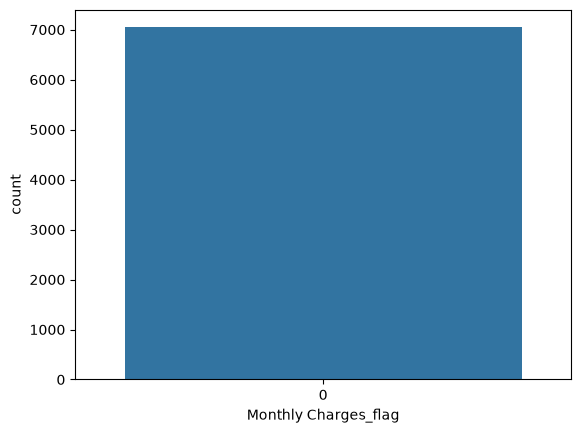

Number of outliers that they are less than lower outer fence(-127.54999999999998):  0 
Number of outliers that they are greater than upper outer fence (252.89999999999998) :  0


Monthly Charges_flag
0    7043
Name: count, dtype: int64

In [132]:
colunm_outliers(churn,'Monthly Charges')

In [133]:
churn.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason,TotalCharge_CityRatio,Monthly Charges_flag
0,Los Angeles,0,0,0,0,2,1,0,2,1,1,0,0,0,0,0,1,0,53.85,108.15,1,86,3239,Competitor,0.096666,0
1,Los Angeles,1,0,0,1,2,1,0,1,0,0,0,0,0,0,0,1,1,70.70,151.65,1,67,2701,Other Reason,0.135547,0
2,Los Angeles,1,0,0,1,8,1,1,1,0,0,1,0,1,1,0,1,1,99.65,820.50,1,86,5372,Other Reason,0.733375,0
3,Los Angeles,1,0,1,1,28,1,1,1,0,0,1,1,1,1,0,1,1,104.80,3046.05,1,84,5003,Other Reason,2.722605,0
4,Los Angeles,0,0,0,1,49,1,1,1,0,1,1,0,1,1,0,1,2,103.70,5036.30,1,89,5340,Competitor,4.501519,0


### As there are no outliers in 'Monthly Charges_flag' so drop this column

In [134]:
churn=churn.drop(columns='Monthly Charges_flag')
churn.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason,TotalCharge_CityRatio
0,Los Angeles,0,0,0,0,2,1,0,2,1,1,0,0,0,0,0,1,0,53.85,108.15,1,86,3239,Competitor,0.096666
1,Los Angeles,1,0,0,1,2,1,0,1,0,0,0,0,0,0,0,1,1,70.70,151.65,1,67,2701,Other Reason,0.135547
2,Los Angeles,1,0,0,1,8,1,1,1,0,0,1,0,1,1,0,1,1,99.65,820.50,1,86,5372,Other Reason,0.733375
3,Los Angeles,1,0,1,1,28,1,1,1,0,0,1,1,1,1,0,1,1,104.80,3046.05,1,84,5003,Other Reason,2.722605
4,Los Angeles,0,0,0,1,49,1,1,1,0,1,1,0,1,1,0,1,2,103.70,5036.30,1,89,5340,Competitor,4.501519


### Outliers in 'Total Charges'

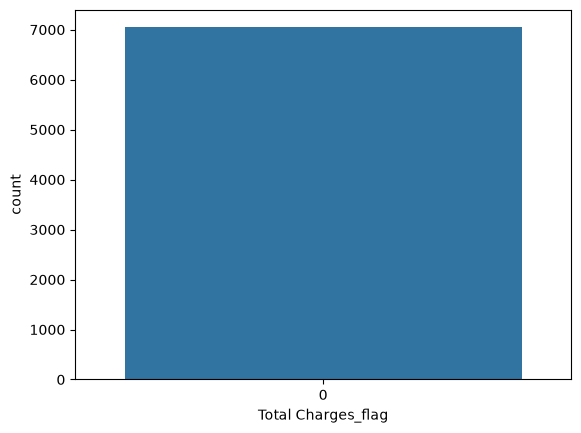

Number of outliers that they are less than lower outer fence(-9750.9):  0 
Number of outliers that they are greater than upper outer fence (13939.725) :  0


Total Charges_flag
0    7043
Name: count, dtype: int64

In [135]:
colunm_outliers(churn,'Total Charges')

In [136]:
churn.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason,TotalCharge_CityRatio,Total Charges_flag
0,Los Angeles,0,0,0,0,2,1,0,2,1,1,0,0,0,0,0,1,0,53.85,108.15,1,86,3239,Competitor,0.096666,0
1,Los Angeles,1,0,0,1,2,1,0,1,0,0,0,0,0,0,0,1,1,70.70,151.65,1,67,2701,Other Reason,0.135547,0
2,Los Angeles,1,0,0,1,8,1,1,1,0,0,1,0,1,1,0,1,1,99.65,820.50,1,86,5372,Other Reason,0.733375,0
3,Los Angeles,1,0,1,1,28,1,1,1,0,0,1,1,1,1,0,1,1,104.80,3046.05,1,84,5003,Other Reason,2.722605,0
4,Los Angeles,0,0,0,1,49,1,1,1,0,1,1,0,1,1,0,1,2,103.70,5036.30,1,89,5340,Competitor,4.501519,0


### As there are no Outliers in 'Total Charges', so drop 'Total Charges_flag'

In [137]:
churn=churn.drop(columns='Total Charges_flag')
churn.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason,TotalCharge_CityRatio
0,Los Angeles,0,0,0,0,2,1,0,2,1,1,0,0,0,0,0,1,0,53.85,108.15,1,86,3239,Competitor,0.096666
1,Los Angeles,1,0,0,1,2,1,0,1,0,0,0,0,0,0,0,1,1,70.70,151.65,1,67,2701,Other Reason,0.135547
2,Los Angeles,1,0,0,1,8,1,1,1,0,0,1,0,1,1,0,1,1,99.65,820.50,1,86,5372,Other Reason,0.733375
3,Los Angeles,1,0,1,1,28,1,1,1,0,0,1,1,1,1,0,1,1,104.80,3046.05,1,84,5003,Other Reason,2.722605
4,Los Angeles,0,0,0,1,49,1,1,1,0,1,1,0,1,1,0,1,2,103.70,5036.30,1,89,5340,Competitor,4.501519


### Handling Missing Values

In [138]:
percentage_of_miss(churn)

,Number of Missing,Percentage of Miss


## Handling Missing Values (Future Dataset)

This dataset has no missing values but future data might have it. The following code uses MICE to handle missing values

In [139]:
# -------------------------------
# 1) Auto-infer column types
# -------------------------------
def split_cols(df: pd.DataFrame):
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
    return num_cols, cat_cols

# Choose a numeric subset for MICE (e.g., those with missingness)
def choose_mice_numeric_cols(df: pd.DataFrame, max_cols: int = 30):
    num_cols, _ = split_cols(df)
    # sort numeric columns by missing rate descending; pick top up to max_cols
    miss_rates = df[num_cols].isna().mean().sort_values(ascending=False)
    mice_cols = [c for c in miss_rates.index if miss_rates[c] > 0][:max_cols]
    other_num = [c for c in num_cols if c not in mice_cols]
    return mice_cols, other_num

# -------------------------------
# 2) Build scalable preprocessors
# -------------------------------
def build_pipeline(X_train: pd.DataFrame,
                   mice_max_cols: int = 30,
                   n_nearest_features: int = 20):
    mice_num_cols, other_num_cols = choose_mice_numeric_cols(X_train, mice_max_cols)
    _, cat_cols = split_cols(X_train)

    # (a) MICE on selected numeric columns only
    mice_block = Pipeline([
        ('imp_mice', IterativeImputer(
            random_state=42,
            max_iter=10,
            initial_strategy='median',
            n_nearest_features=min(n_nearest_features, max(1, len(mice_num_cols))),
            sample_posterior=False,
            tol=1e-3
        ))
    ])

    # (b) Simple median for the rest of numeric columns
    other_num_block = Pipeline([
        ('imp_med', SimpleImputer(strategy='median'))
    ])

    # (c) Categorical imputation (robust + cheap)
    # Use "Unknown" (or most_frequent). No OHE here since we’re returning imputed features, not modeling.
    cat_block = Pipeline([
        ('imp_cat', SimpleImputer(strategy='constant', fill_value='Unknown'))
    ])

    pre = ColumnTransformer(
        transformers=[
            ('mice_num', mice_block, mice_num_cols),
            ('med_num', other_num_block, other_num_cols),
            ('cat',      cat_block,   cat_cols),
        ],
        remainder='passthrough'
    ).set_output(transform='pandas')

    return pre, {'mice_num': mice_num_cols, 'med_num': other_num_cols, 'cat': cat_cols}


In [140]:
# Separate features and target
X_train = churn.drop(columns=['Churn Value'])  # everything except target
y_train = churn['Churn Value'] 

In [141]:
percentage_of_miss(X_train)

,Number of Missing,Percentage of Miss


In [142]:
# -------------------------------
# 3) Fit on TRAIN, reuse for FUTURE
# -------------------------------
pre, cols = build_pipeline(X_train, mice_max_cols=30, n_nearest_features=20)
pre.fit(X_train)
X_train_imputed = pre.transform(X_train)
joblib.dump(pre, 'imputer_hybrid.joblib')

['imputer_hybrid.joblib']

In [143]:
percentage_of_miss(X_train_imputed)

,Number of Missing,Percentage of Miss


In [144]:
X_train.head(2)

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Score,CLTV,Churn Reason,TotalCharge_CityRatio
0,Los Angeles,0,0,0,0,2,1,0,2,1,1,0,0,0,0,0,1,0,53.85,108.15,86,3239,Competitor,0.096666
1,Los Angeles,1,0,0,1,2,1,0,1,0,0,0,0,0,0,0,1,1,70.70,151.65,67,2701,Other Reason,0.135547


In [145]:
X_train.columns

Index(['City', 'Gender', 'Senior Citizen', 'Partner', 'Dependents',
       'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Score',
       'CLTV', 'Churn Reason', 'TotalCharge_CityRatio'],
      dtype='object')

### Fix the Prefixes

In [146]:
def strip_prefixes(df: pd.DataFrame) -> pd.DataFrame:
    """Remove the ColumnTransformer prefixes like 'mice_num__' or 'cat__'."""
    df = df.copy()
    df.columns = [re.sub(r'.*?__', '', c) for c in df.columns]
    """
    re.sub(pattern, replacement, text)
    replaces any part of text matching pattern with replacement.
    
    Pattern explanation:
    
    .*? → “any character (.) repeated zero or more times (*), but as few as possible (?)”.
    This lazily captures everything at the start of the string, regardless of underscores.
    
    __ → the double underscore itself.
    
    Together, .*?__ means:
    “Match everything from the start of the string up to and including the first occurrence of a double underscore.”
    
    Replacement is an empty string '',
    so the matched prefix (for example mice_num__ or cat__) is removed.
    """
    return df

In [147]:
X_train= strip_prefixes(X_train)

In [148]:
# For DT, Randome Forest, and Extra Trees

def handle_missing_for_dt(df):
    df = df.copy()

    for col in df.columns:

        # only create missing indicator if column has missing values
        if df[col].isna().any():
            df[col + "_missing"] = df[col].isna().astype(int)

        # numeric columns
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(9999999)

        # categorical/text columns
        else:
            df[col] = df[col].fillna("UnKnown")

    return df

### Separate features and target
- Churn Value is the target variable, so drop it
- Drop  Churn Score, Churn Reason, CLTV entirely before training the model because they cause direct data leakage.

In [149]:
churn_copy=churn.copy()

In [150]:
columns_to_drop=['Churn Value','Churn Score','Churn Reason','CLTV']

In [151]:
X=churn.drop(columns=columns_to_drop) # all the columns except target
y=churn['Churn Value']

### Split into Train and Test

In [152]:
# Split into train and test sets FIRST to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Initialize the Target Encoder specifically for the 'City' column

In [153]:
encoder = ce.TargetEncoder(cols=["City"])

### Fit on training data nad transform on train and test data

In [154]:
X_train['City_Encoded']=encoder.fit_transform(X_train['City'],y_train)
X_test['City_Encoded']=encoder.transform(X_test['City'])

In [155]:
X_train.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,TotalCharge_CityRatio,City_Encoded
2142,San Diego,0,0,1,0,71,1,1,1,0,0,1,0,1,1,1,1,3,98.65,6962.85,4.937316,0.300812
1623,Jamestown,1,0,0,0,16,1,0,1,0,1,1,0,0,1,0,1,3,93.20,1573.70,0.442545,0.356923
6074,Littlerock,1,0,0,0,32,1,1,1,0,1,1,0,1,1,1,1,3,104.05,3416.85,1.723049,0.220463
1362,El Monte,1,1,1,0,24,0,2,2,0,0,1,0,0,1,0,1,3,40.65,933.30,1.088936,0.334366
6754,Los Angeles,1,0,1,1,20,1,0,0,2,2,2,2,2,2,0,0,0,20.05,406.05,0.362934,0.294355


In [156]:
X_test.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,TotalCharge_CityRatio,City_Encoded
185,Keene,1,0,0,0,15,1,0,1,0,1,0,0,0,1,0,1,2,85.9,1269.55,1.535081,0.294678
2715,Stockton,0,0,1,0,18,1,1,2,0,1,0,0,0,0,0,0,3,56.8,1074.65,1.048260,0.263921
3825,San Leandro,1,0,0,0,2,1,0,0,2,2,2,2,2,2,0,1,0,20.0,40.90,0.036996,0.223370
1807,Sherman Oaks,0,1,1,0,6,1,0,1,0,1,0,0,0,1,0,1,1,84.2,519.15,0.509295,0.266087
132,Murrieta,0,0,0,0,40,1,1,1,0,0,1,1,1,1,0,0,2,104.8,4131.95,1.183202,0.235492


### Now Drop 'City' column as it has been target encoded

In [157]:
X_train = X_train.drop(columns=["City"])
X_test = X_test.drop(columns=["City"])

In [158]:
X_train.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,TotalCharge_CityRatio,City_Encoded
2142,0,0,1,0,71,1,1,1,0,0,1,0,1,1,1,1,3,98.65,6962.85,4.937316,0.300812
1623,1,0,0,0,16,1,0,1,0,1,1,0,0,1,0,1,3,93.20,1573.70,0.442545,0.356923
6074,1,0,0,0,32,1,1,1,0,1,1,0,1,1,1,1,3,104.05,3416.85,1.723049,0.220463
1362,1,1,1,0,24,0,2,2,0,0,1,0,0,1,0,1,3,40.65,933.30,1.088936,0.334366
6754,1,0,1,1,20,1,0,0,2,2,2,2,2,2,0,0,0,20.05,406.05,0.362934,0.294355


In [159]:
X_train.select_dtypes(include='object').columns

Index([], dtype='object')

In [160]:
categorical_cols=X_train.select_dtypes(include='object').columns
encoder = OneHotEncoder(handle_unknown='ignore', #drop='first', 
                        #sparse=False
                       sparse_output=False #sparse was removed and replaced with:sparse_output
                       )

'''
drop='first' → avoids dummy variable trap

handle_unknown='ignore' → prevents crash on new categories in test data

sparse=False → returns DataFrame-friendly output
'''

#FIT on TRAIN ONLY (no data leakage)
encoder.fit(X_train[categorical_cols])

#Transform Train & Test
X_train_encoded = encoder.transform(X_train[categorical_cols])
X_test_encoded  = encoder.transform(X_test[categorical_cols])

#Convert back to DataFrame with proper column names
encoded_cols = encoder.get_feature_names_out(categorical_cols)

X_train_encoded_df = pd.DataFrame(X_train_encoded, columns=encoded_cols, index=X_train.index)
X_test_encoded_df  = pd.DataFrame(X_test_encoded,  columns=encoded_cols, index=X_test.index)

# Drop original categorical columns & attach encoded ones
X_train_2 = X_train.drop(columns=categorical_cols)
X_test_2  = X_test.drop(columns=categorical_cols)

X_train_encoded = pd.concat([X_train_2, X_train_encoded_df], axis=1)
X_test_encoded  = pd.concat([X_test_2, X_test_encoded_df], axis=1)

In [161]:
X_train_encoded

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,TotalCharge_CityRatio,City_Encoded
2142,0,0,1,0,71,1,1,1,0,0,1,0,1,1,1,1,3,98.65,6962.85,4.937316,0.300812
1623,1,0,0,0,16,1,0,1,0,1,1,0,0,1,0,1,3,93.20,1573.70,0.442545,0.356923
6074,1,0,0,0,32,1,1,1,0,1,1,0,1,1,1,1,3,104.05,3416.85,1.723049,0.220463
1362,1,1,1,0,24,0,2,2,0,0,1,0,0,1,0,1,3,40.65,933.30,1.088936,0.334366
6754,1,0,1,1,20,1,0,0,2,2,2,2,2,2,0,0,0,20.05,406.05,0.362934,0.294355
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3772,1,0,1,1,42,1,0,1,0,0,1,1,1,1,2,1,1,100.40,4303.65,3.432622,0.279045
5191,1,0,0,0,39,1,0,0,2,2,2,2,2,2,2,0,3,20.70,762.45,1.382126,0.216939
5226,0,0,1,1,19,1,0,0,2,2,2,2,2,2,2,0,0,20.20,387.40,0.945282,0.323440
5390,0,0,1,1,35,1,0,0,2,2,2,2,2,2,1,0,1,19.90,666.00,0.384183,0.250012


In [162]:
X_train_encoded.columns

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges',
       'TotalCharge_CityRatio', 'City_Encoded'],
      dtype='object')

In [163]:
X_test_encoded.columns

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges',
       'TotalCharge_CityRatio', 'City_Encoded'],
      dtype='object')

### Scaling

In [164]:
robust=RobustScaler()
X_train_scaled=robust.fit_transform(X_train_encoded)
X_test_scaled=robust.transform(X_test_encoded)
train_robust=pd.DataFrame(X_train_scaled,columns=X_train_encoded.columns)
test_robust=pd.DataFrame(X_test_scaled,columns=X_test_encoded.columns)
train_robust

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,TotalCharge_CityRatio,City_Encoded
0,0.0,0.0,1.0,0.0,0.913043,0.0,0.0,0.0,-1.0,-1.0,0.0,-1.0,0.0,0.0,1.0,0.0,2.0,0.515866,1.653837,2.627103,0.593140
1,1.0,0.0,0.0,0.0,-0.282609,0.0,-1.0,0.0,-1.0,0.0,0.0,-1.0,-1.0,0.0,0.0,0.0,2.0,0.417044,0.054451,-0.371952,1.387884
2,1.0,0.0,0.0,0.0,0.065217,0.0,0.0,0.0,-1.0,0.0,0.0,-1.0,0.0,0.0,1.0,0.0,2.0,0.613781,0.601459,0.482442,-0.544898
3,1.0,1.0,1.0,0.0,-0.108696,-1.0,1.0,1.0,-1.0,-1.0,0.0,-1.0,-1.0,0.0,0.0,0.0,2.0,-0.535811,-0.135606,0.059341,1.068397
4,1.0,0.0,1.0,1.0,-0.195652,0.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,-1.0,-1.0,-0.909338,-0.292082,-0.425071,0.501687
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,1.0,0.0,1.0,1.0,0.282609,0.0,-1.0,0.0,-1.0,-1.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.547597,0.864643,1.623123,0.284839
5630,1.0,0.0,0.0,0.0,0.217391,0.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,-1.0,2.0,-0.897552,-0.186310,0.254967,-0.594815
5631,0.0,0.0,1.0,1.0,-0.217391,0.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,-1.0,-1.0,-0.906618,-0.297617,-0.036510,0.913646
5632,0.0,0.0,1.0,1.0,0.130435,0.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,0.0,-0.912058,-0.214935,-0.410893,-0.126378


In [165]:
churn['Partner'].dtypes

dtype('int64')